# Refractory violations: Denis' pipeline with my mask midline, all 71 Kaden 4-fish recordings

**Run used** (no new assignment here): `EODAssignment/analysis/social_electric_fish_runners/run_kaden_denis_all.sh` (stage `denis_table`,
2026-11-06), output in `results/eod_assign_4fish_kaden/<t>/denis_assignments.csv`, one folder per recording of 2024-02-20.
- Denis' pipeline (his 1/r field with mirror images, **no refractory step**), with my mask midline on Kaden's visible masks.
  Masks are taken at the EOD's own video frame (no offset), identity = Kaden's letters A–D.
- Two picks per EOD:
  - **similarity**: Denis' own rule, the highest cosine similarity;
  - **L2**: the smallest L2 between the recorded and predicted 10-pair patterns, each scaled to max |v| = 1.
- An EOD is assigned only when every fish has a midline (95.4% of 3.67 M EODs).

**Refractory violation.** Two consecutive detected EODs (in time, `Time`) less than **6 ms** apart, both given to the same fish.
- This is the rule of `EOD_denis_mask_midline_kaden_4fish_summary.ipynb` (14 recordings, 2026-11-03).
- **10 ms**, the rule of `EOD_assignment_4fish_6recordings.ipynb`, is reported as well.
- Pairs are formed over **all detected EODs**, so an unassigned EOD still sits between its neighbours. A pair counts only when both of
  its EODs are assigned. (The 14-video summary dropped the unassigned EODs first, which joins EODs that were not consecutive; section 5
  compares the two.)
- Reported as a % of all valid consecutive pairs, and as a % of the valid pairs closer than the limit.

**Chance level** (no shuffling is run). It is the expected number of violations if the fish labels were shuffled across the
recording's assigned EODs, with each fish keeping its number of EODs and every interval kept:
$$\text{close pairs} \times \sum_f \frac{n_f (n_f - 1)}{N (N - 1)} \;\approx\; \text{close pairs} \times \sum_f p_f^2 ,$$
with $n_f$ the number of EODs given to fish f and N the total.

In [1]:
import glob, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

BASE = 'results/eod_assign_4fish_kaden'
OUT = f'{BASE}/refractory_violations'
os.makedirs(OUT, exist_ok=True)
FISH = 'ABCD'
PICKS = {'similarity': 'fish | Denis, similarity', 'L2': 'fish | Denis, L2 (max |v| = 1)'}
LIMITS_MS = [6.0, 6.5, 10.0]
COLORS = {'A': 'C0', 'B': 'C1', 'C': 'C2', 'D': 'C3'}
PICK_STYLE = {'similarity': dict(color='#1F5FBF', marker='o'), 'L2': dict(color='#C8361E', marker='s')}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3'})

RECS = sorted(os.path.basename(os.path.dirname(p)) for p in glob.glob(f'{BASE}/*/denis_assignments.csv'))
hours = lambda t: int(t[:2]) + int(t[3:5]) / 60 + int(t[6:8]) / 3600
print(len(RECS), 'recordings,', RECS[0], '...', RECS[-1])

71 recordings, 00_12_52 ... 23_56_27


In [2]:
def load(t):
    '''All detected EODs of one recording, in time order: dt to the previous EOD (ms) and the fish index of each pick (-1 = unassigned).'''
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['Time'] + list(PICKS.values()), keep_default_na=False)
    assert np.all(np.diff(d.Time.to_numpy()) >= 0), t
    lab = {p: d[c].map({f: i for i, f in enumerate(FISH)}).fillna(-1).astype(int).to_numpy() for p, c in PICKS.items()}
    return np.diff(d.Time.to_numpy()) * 1000, lab

def chance(k, close):
    # expected violations (total, per fish) under shuffled labels: close pairs x P(two random assigned EODs share a fish)
    n = np.bincount(k[k >= 0], minlength=4).astype(float); N = n.sum()
    pf = n * (n - 1) / (N * (N - 1))
    return close.sum() * pf.sum(), close.sum() * pf

rows, per_fish, DT = [], [], {p: [] for p in PICKS}
for t in RECS:
    dt, lab = load(t)
    for p, k in lab.items():
        valid = (k[1:] >= 0) & (k[:-1] >= 0)
        same = valid & (k[1:] == k[:-1])
        DT[p].append(pd.DataFrame({'dt_ms': dt[valid], 'same': same[valid], 'rec': t}))
        n_assigned = (k >= 0).sum(); share = np.bincount(k[k >= 0], minlength=4) / n_assigned
        for lim in LIMITS_MS:
            close = valid & (dt < lim)
            v = (same & close).sum()
            ex, exf = chance(k, close)
            r = dict(recording=t, hour=hours(t), pick=p, limit_ms=lim, EODs=len(k), assigned=n_assigned,
                     valid_pairs=valid.sum(), close_pairs=close.sum(), violations=v,
                     **{f'% EODs {f}': 100 * share[i] for i, f in enumerate(FISH)})
            for name, den in [('of valid pairs', valid.sum()), ('of close pairs', close.sum())]:
                r[f'% violations {name}'] = 100 * v / den
                r[f'% violations {name}, chance'] = 100 * ex / den
            rows.append(r)
            for i, f in enumerate(FISH):
                per_fish.append(dict(recording=t, pick=p, limit_ms=lim, fish=f, violations=(same & close & (k[1:] == i)).sum(),
                                     chance=exf[i], EODs=(k == i).sum()))

R = pd.DataFrame(rows); PF = pd.DataFrame(per_fish); DT = {p: pd.concat(v, ignore_index=True) for p, v in DT.items()}
R.to_csv(f'{OUT}/refractory_violations_per_recording.csv', index=False)
PF.to_csv(f'{OUT}/refractory_violations_per_fish.csv', index=False)
r6 = R[(R.pick == 'similarity') & (R.limit_ms == 6)]
print(f'{r6.EODs.sum():,} EODs, {r6.assigned.sum():,} assigned, {len(RECS)} recordings')

3,667,494 EODs, 3,498,433 assigned, 71 recordings


## 1. All recordings together

In [3]:
def pooled(g):
    obs = g.violations.sum()
    sh = (g['% violations of valid pairs, chance'] * g.valid_pairs / 100).sum()
    return pd.Series({'valid pairs': g.valid_pairs.sum(), 'close pairs': g.close_pairs.sum(),
                      '% of valid pairs that are close': 100 * g.close_pairs.sum() / g.valid_pairs.sum(),
                      'violations': obs, 'chance violations': sh,
                      '% violations of valid pairs': 100 * obs / g.valid_pairs.sum(),
                      '% violations of valid pairs, chance': 100 * sh / g.valid_pairs.sum(),
                      '% violations of close pairs': 100 * obs / g.close_pairs.sum(),
                      '% violations of close pairs, chance': 100 * sh / g.close_pairs.sum(),
                      'observed / chance': obs / sh,
                      'recordings below chance': (g['% violations of valid pairs'] < g['% violations of valid pairs, chance']).sum()})

P = R.groupby(['limit_ms', 'pick'], sort=False).apply(pooled, include_groups=False)
P.to_csv(f'{OUT}/refractory_violations_pooled.csv')
P.round(3)

,,valid pairs,close pairs,% of valid pairs that are close,violations,chance violations,% violations of valid pairs,"% violations of valid pairs, chance",% violations of close pairs,"% violations of close pairs, chance",observed / chance,recordings below chance
limit_ms,pick,,,,,,,,,,,
6.0,similarity,3487983.0,557674.0,15.988,15798.0,147913.950,0.453,4.241,2.833,26.523,0.107,71.0
6.5,similarity,3487983.0,609930.0,17.487,17300.0,161782.754,0.496,4.638,2.836,26.525,0.107,71.0
10.0,similarity,3487983.0,971502.0,27.853,28432.0,257798.482,0.815,7.391,2.927,26.536,0.110,71.0
6.0,L2,3487983.0,557674.0,15.988,16004.0,147830.604,0.459,4.238,2.870,26.508,0.108,71.0
6.5,L2,3487983.0,609930.0,17.487,17520.0,161691.413,0.502,4.636,2.872,26.510,0.108,71.0
10.0,L2,3487983.0,971502.0,27.853,28763.0,257652.352,0.825,7.387,2.961,26.521,0.112,71.0


## 2. Per recording, across the day

Top: % of all valid consecutive pairs. Bottom: % of the close pairs (< 6 ms) given to the same fish. Open markers: chance.

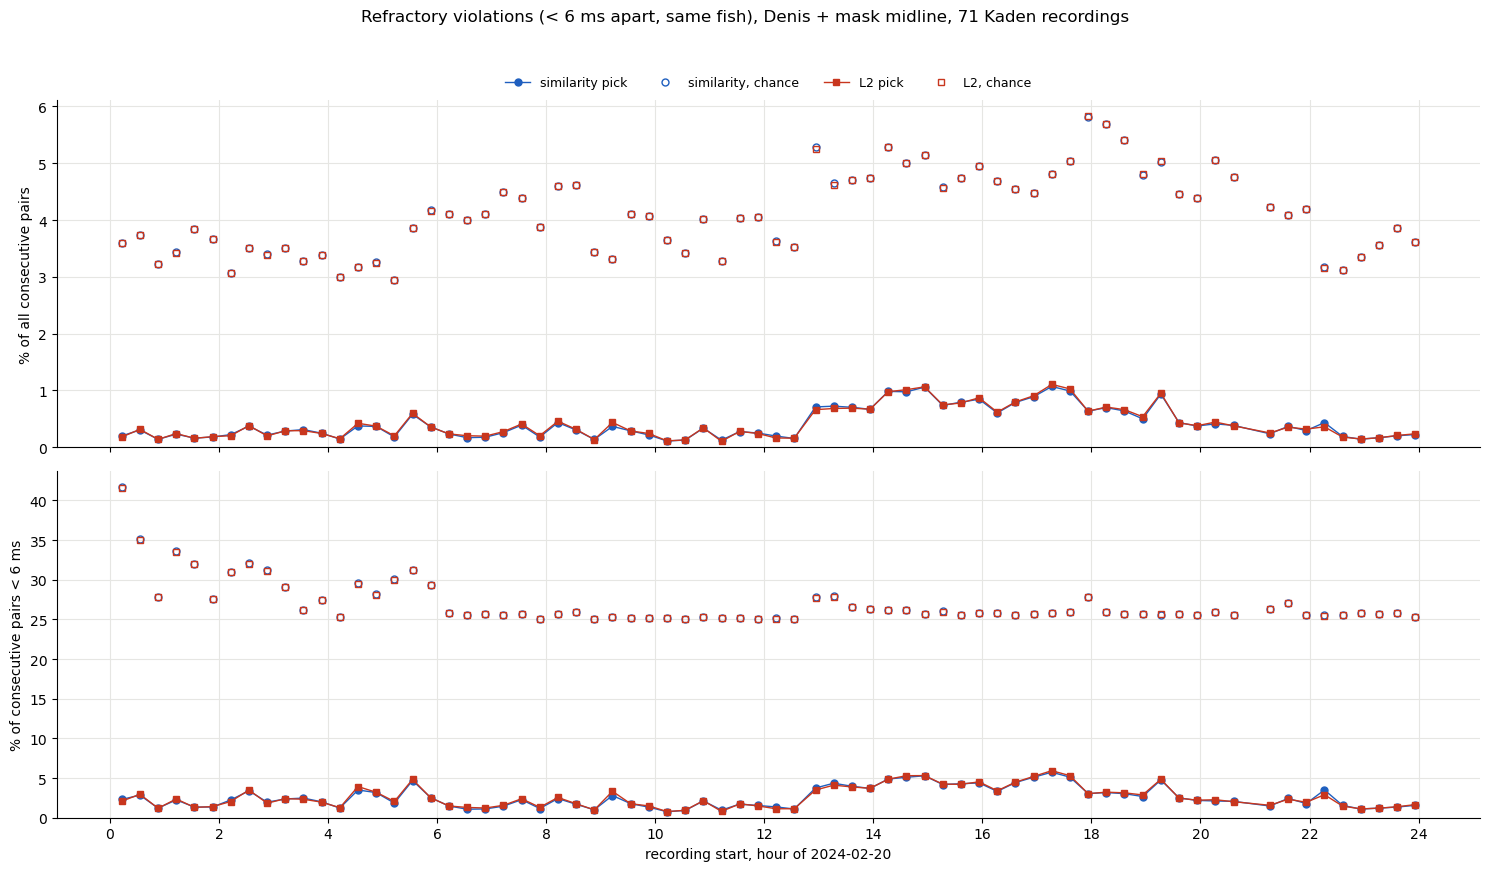

In [4]:
def plot_day(lim, fname):
    fig, axs = plt.subplots(2, 1, figsize=(15, 8.5), sharex=True)
    for ax, name, ylab in [(axs[0], 'of valid pairs', '% of all consecutive pairs'),
                           (axs[1], 'of close pairs', f'% of consecutive pairs < {lim:g} ms')]:
        for p, st in PICK_STYLE.items():
            g = R[(R.pick == p) & (R.limit_ms == lim)].sort_values('hour')
            ax.plot(g.hour, g[f'% violations {name}'], '-', lw=1, ms=5, label=f'{p} pick', **st)
            ax.plot(g.hour, g[f'% violations {name}, chance'], ls='none', mfc='none', ms=5, label=f'{p}, chance', **st)
        ax.set_ylabel(ylab); ax.set_ylim(0, None)
    axs[1].set_xlabel('recording start, hour of 2024-02-20'); axs[1].set_xticks(range(0, 25, 2))
    axs[0].legend(ncol=5, fontsize=9, loc='lower center', bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.suptitle(f'Refractory violations (< {lim:g} ms apart, same fish), Denis + mask midline, 71 Kaden recordings', y=1.02)
    plt.tight_layout(); fig.savefig(f'{OUT}/{fname}', dpi=120, bbox_inches='tight'); plt.show()

plot_day(6.0, 'refractory_violations_per_recording_6ms.png')

**Median across the 71 videos, < 6.5 ms.** One point per video (its % violations), against the recording's start time; dashed
line and label: the median over the 71 videos for each pick. Chance is left out here so the y axis shows the observed values; its
median is given in the title. The same plot at 6 ms follows for comparison.

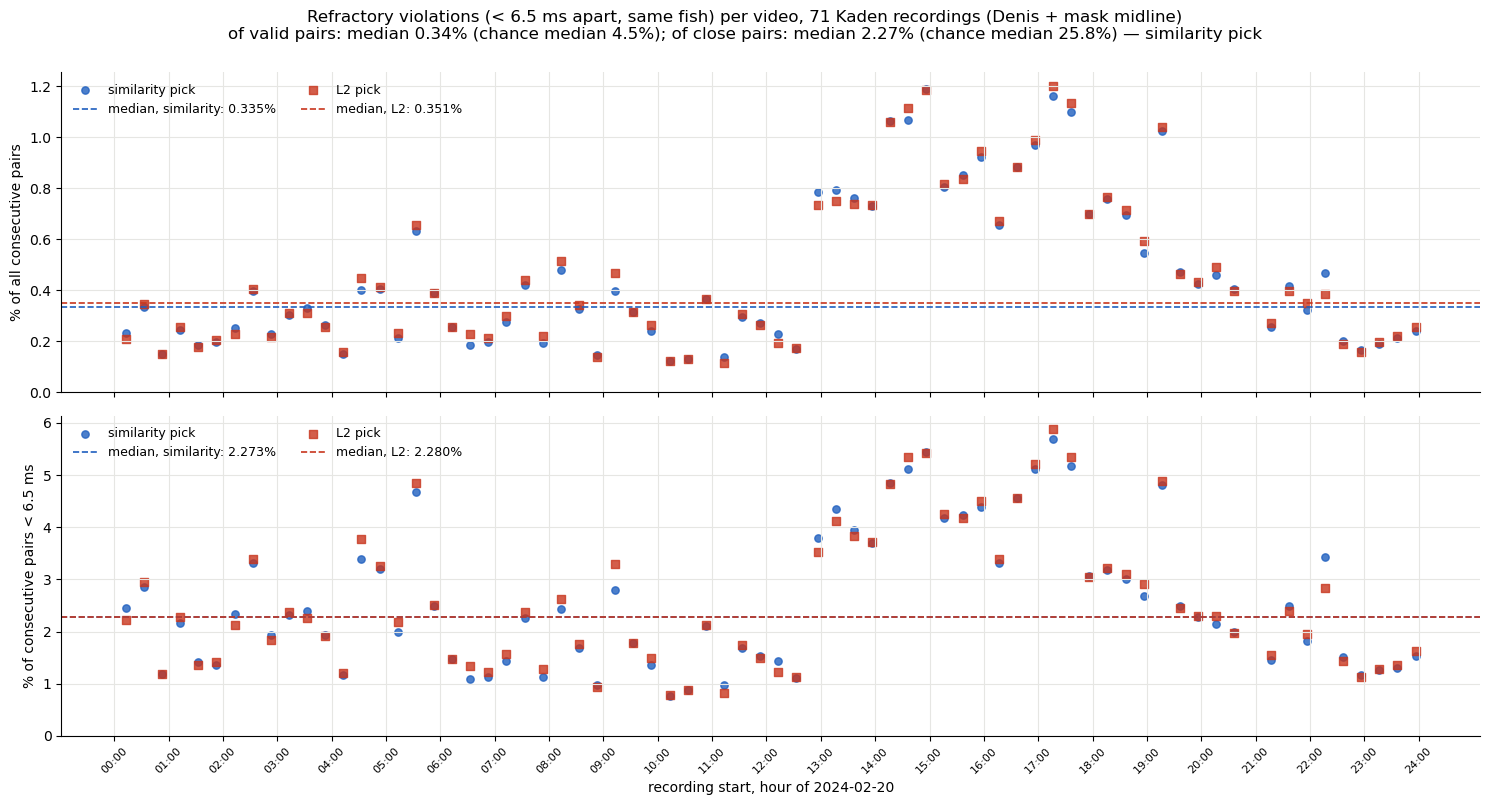

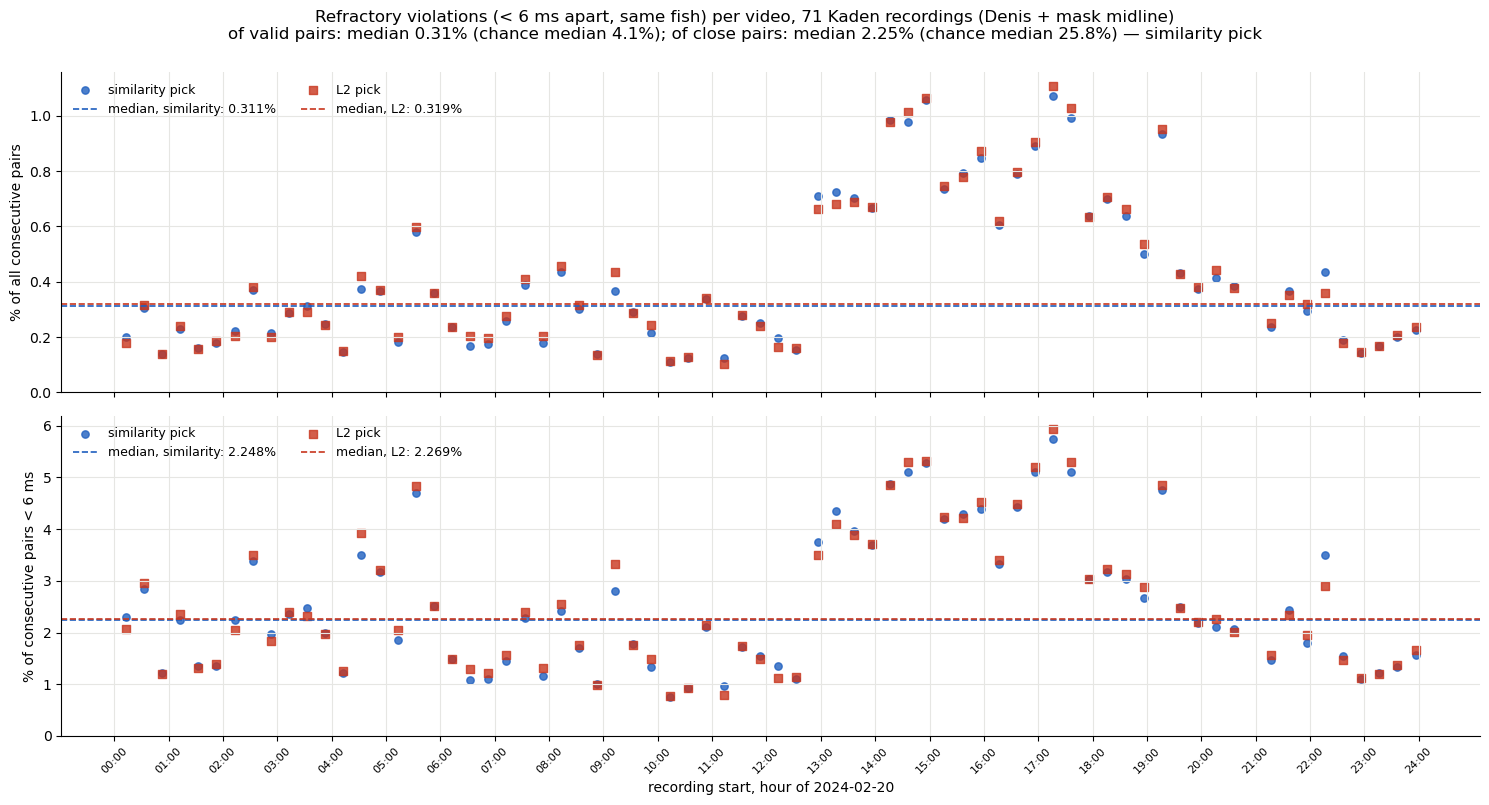

,,% violations of valid pairs,% violations of close pairs,"% violations of valid pairs, chance"
limit_ms,pick,,,
6.0,similarity,0.311,2.248,4.073
6.5,similarity,0.335,2.273,4.452
10.0,similarity,0.598,2.279,7.080
6.0,L2,0.319,2.269,4.073
6.5,L2,0.351,2.280,4.452
10.0,L2,0.605,2.333,7.082


In [5]:
def plot_median_scatter(lim, fname):
    fig, axs = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
    titles = []
    for ax, name, ylab in [(axs[0], 'of valid pairs', '% of all consecutive pairs'),
                           (axs[1], 'of close pairs', f'% of consecutive pairs < {lim:g} ms')]:
        for p, st in PICK_STYLE.items():
            g = R[(R.pick == p) & (R.limit_ms == lim)].sort_values('hour')
            med = g[f'% violations {name}'].median()
            ax.scatter(g.hour, g[f'% violations {name}'], s=28, color=st['color'], marker=st['marker'], alpha=0.8,
                       label=f'{p} pick')
            ax.axhline(med, color=st['color'], ls='--', lw=1.2, label=f'median, {p}: {med:.3f}%')
            if p == 'similarity':
                titles.append(f"{name}: median {med:.2f}% (chance median {g[f'% violations {name}, chance'].median():.1f}%)")
        ax.set_ylabel(ylab); ax.set_ylim(0, None); ax.legend(fontsize=9, frameon=False, ncol=2, loc='upper left')
    axs[1].set_xlabel('recording start, hour of 2024-02-20'); axs[1].set_xticks(range(0, 25, 1))
    axs[1].set_xticklabels([f'{h:02d}:00' for h in range(25)], rotation=45, fontsize=8)
    fig.suptitle(f'Refractory violations (< {lim:g} ms apart, same fish) per video, 71 Kaden recordings (Denis + mask midline)\n'
                 + '; '.join(titles) + ' — similarity pick', y=1.0)
    plt.tight_layout(); fig.savefig(f'{OUT}/{fname}', dpi=120, bbox_inches='tight'); plt.show()

plot_median_scatter(6.5, 'refractory_violations_median_scatter_6.5ms.png')
plot_median_scatter(6.0, 'refractory_violations_median_scatter_6ms.png')

MED = R.groupby(['limit_ms', 'pick'], sort=False)[['% violations of valid pairs', '% violations of close pairs',
                                                    '% violations of valid pairs, chance']].median()
MED.to_csv(f'{OUT}/refractory_violations_median_over_videos.csv')
MED.round(3)

In [6]:
cols = ['recording', 'pick', 'assigned', 'close_pairs', 'violations', '% violations of valid pairs',
        '% violations of valid pairs, chance', '% violations of close pairs', '% violations of close pairs, chance', '% EODs B']
print('the 10 recordings with the highest % violations of close pairs (similarity pick, 6 ms):')
display(R[(R.limit_ms == 6) & (R.pick == 'similarity')].nlargest(10, '% violations of close pairs')[cols].round(3))

the 10 recordings with the highest % violations of close pairs (similarity pick, 6 ms):


,recording,pick,assigned,close_pairs,violations,% violations of valid pairs,"% violations of valid pairs, chance",% violations of close pairs,"% violations of close pairs, chance",% EODs B
306,17_16_24,similarity,55025,10251,588,1.070,4.817,5.736,25.825,19.637
264,14_56_23,similarity,58355,11672,617,1.058,5.153,5.286,25.741,21.107
312,17_36_24,similarity,62918,12189,623,0.990,5.033,5.111,25.970,16.560
300,16_56_24,similarity,51349,8929,456,0.889,4.471,5.107,25.696,22.666
258,14_36_23,similarity,61339,11723,598,0.975,5.008,5.101,26.192,16.026
252,14_16_23,similarity,64587,13021,635,0.983,5.284,4.877,26.204,15.920
342,19_16_25,similarity,60092,11797,562,0.935,5.029,4.764,25.610,18.671
96,05_32_55,similarity,41030,5010,235,0.580,3.857,4.691,31.200,4.387
294,16_36_24,similarity,56036,9970,442,0.789,4.551,4.433,25.578,19.639
282,15_56_23,similarity,58584,11277,495,0.845,4.960,4.389,25.758,18.473


## 3. Same-fish fraction against the interval

For every valid consecutive pair: is it given to the same fish, against the interval to the previous EOD (0.5 ms bins).
- With a perfect assignment the same-fish fraction would be ~0 below the fish's refractory period, and would rise after it.
- Dashed: the chance level Σ p_f² (each fish's share of the assigned EODs, pooled over recordings).

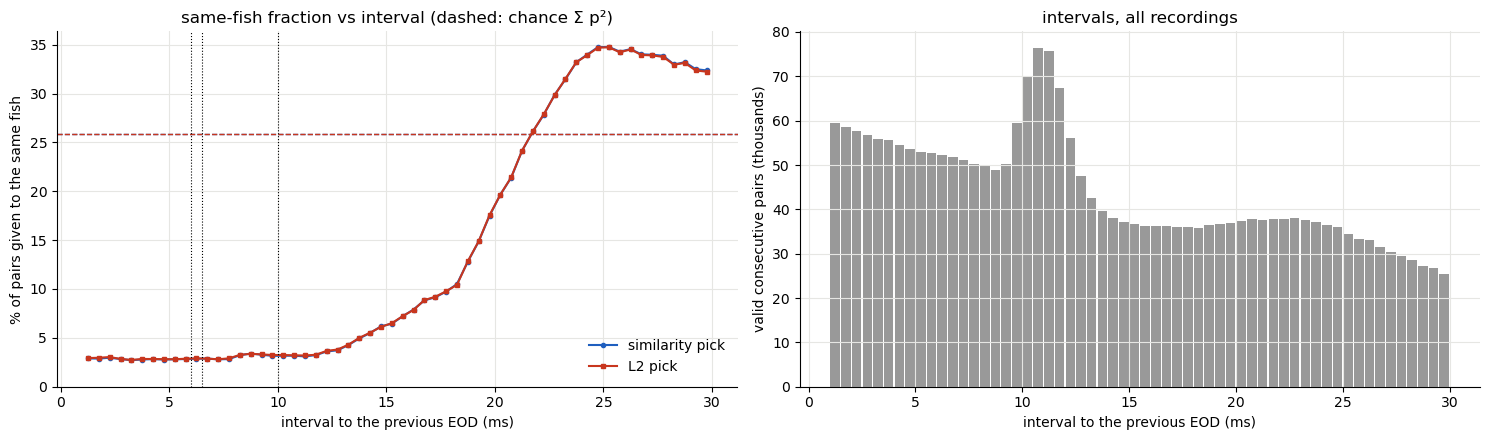

In [7]:
bins = np.arange(1, 30.5, 0.5); mid = (bins[1:] + bins[:-1]) / 2
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for p, st in PICK_STYLE.items():
    d = DT[p]; i = np.digitize(d.dt_ms, bins) - 1; ok = (i >= 0) & (i < len(mid))
    n = np.bincount(i[ok], minlength=len(mid)); s = np.bincount(i[ok], weights=d.same[ok], minlength=len(mid))
    axs[0].plot(mid, 100 * s / np.maximum(n, 1), '-', lw=1.5, ms=3, label=f'{p} pick', **st)
    g = R[(R.pick == p) & (R.limit_ms == 6)]
    sh = (g[[f'% EODs {f}' for f in FISH]].mul(g.assigned, axis=0).sum() / g.assigned.sum() / 100)
    axs[0].axhline(100 * (sh ** 2).sum(), ls='--', lw=1, color=st['color'])
    if p == 'similarity':
        axs[1].bar(mid, n / 1e3, width=0.45, color='0.6')
for lim in LIMITS_MS: axs[0].axvline(lim, color='k', lw=0.8, ls=':')
axs[0].set(xlabel='interval to the previous EOD (ms)', ylabel='% of pairs given to the same fish', ylim=(0, None),
           title='same-fish fraction vs interval (dashed: chance Σ p²)')
axs[0].legend(frameon=False)
axs[1].set(xlabel='interval to the previous EOD (ms)', ylabel='valid consecutive pairs (thousands)', title='intervals, all recordings')
plt.tight_layout(); fig.savefig(f'{OUT}/same_fish_fraction_vs_interval.png', dpi=120); plt.show()

## 4. Which fish get the violations (< 6 ms, all recordings)

Observed violations of each fish (both EODs given to it) against chance. A ratio well below 1 means the timing of that
fish's labels respects the refractory period better than chance.

violations     chance     EODs  observed / chance  \
pick       fish                                                      
similarity A           3842  47678.522  1031796              0.081   
           B           1841  19443.877   613211              0.095   
           C           5024  42759.974   958757              0.117   
           D           5091  38031.578   894669              0.134   
L2         A           3921  47608.516  1031185              0.082   
           B           1907  19424.792   613336              0.098   
           C           5138  42884.153   960789              0.120   
           D           5038  37913.144   893123              0.133   

                 violations per 1000 EODs of the fish  
pick       fish                                        
similarity A                                    3.724  
           B                                    3.002  
           C                                    5.240  
           D                                    5.690  
L2         A                                    3.802  
           B                                    3.109  
           C                                    5.348  
           D                                    5.641

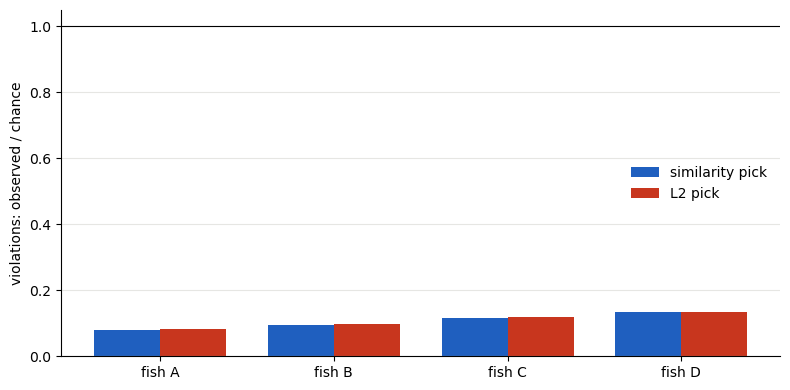

In [8]:
F = PF[PF.limit_ms == 6].groupby(['pick', 'fish'], sort=False)[['violations', 'chance', 'EODs']].sum()
F['observed / chance'] = F.violations / F.chance
F['violations per 1000 EODs of the fish'] = 1000 * F.violations / F.EODs
F.to_csv(f'{OUT}/refractory_violations_per_fish_pooled_6ms.csv')
display(F.round(3))

fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(4); w = 0.38
for j, (p, st) in enumerate(PICK_STYLE.items()):
    ax.bar(x + (j - 0.5) * w, F.loc[p, 'observed / chance'], w, color=st['color'], label=f'{p} pick')
ax.axhline(1, color='k', lw=0.8); ax.set_xticks(x); ax.set_xticklabels([f'fish {f}' for f in FISH])
ax.set_ylabel('violations: observed / chance'); ax.legend(frameon=False); ax.grid(axis='x', visible=False)
plt.tight_layout(); fig.savefig(f'{OUT}/refractory_violations_per_fish_6ms.png', dpi=120); plt.show()

## 5. Check against the 14-video run of 2026-11-03

`EOD_denis_mask_midline_kaden_4fish_summary.ipynb` (`results/eod_assign_4fish/denis_mask_midline_kaden/summary_per_video.csv`, offset 0)
ran the same pipeline on 14 of these recordings. Differences:
- the older run used its own runner and the older EOD tables;
- it formed pairs only from assigned EODs.

So here the similarity pick is recomputed with its pairing as well ("assigned only").

In [9]:
OLD_ALL = pd.read_csv('results/eod_assign_4fish/denis_mask_midline_kaden/summary_per_video.csv')
OLD = OLD_ALL.query('offset == 0').set_index('video'); OLD5 = OLD_ALL.query('offset == -5').set_index('video')
cmp = []
for t in OLD.index.intersection(RECS):
    dt, lab = load(t); d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['Time'])
    k = lab['similarity']; a = k >= 0; ka = k[a]; dta = np.diff(d.Time.to_numpy()[a]) * 1000
    new = R[(R.recording == t) & (R.pick == 'similarity') & (R.limit_ms == 6)].iloc[0]
    cmp.append({'recording': t, 'old run: EODs': OLD.loc[t, 'EODs'], 'this run: assigned': a.sum(),
                'old run: % viol. of all pairs': OLD.loc[t, '% violations of all pairs'],
                'old run, offset -5: % viol. of all pairs': OLD5.loc[t, '% violations of all pairs'],
                'this run, assigned only': 100 * np.mean((dta < 6) & (ka[1:] == ka[:-1])),
                'this run, all detected EODs': new['% violations of valid pairs'],
                'old run: % viol. of pairs < 6 ms': OLD.loc[t, '% violations of pairs < 6 ms'],
                'old run, offset -5: % viol. of pairs < 6 ms': OLD5.loc[t, '% violations of pairs < 6 ms'],
                'this run, all detected EODs, of close pairs': new['% violations of close pairs']})
CMP = pd.DataFrame(cmp).set_index('recording'); CMP.to_csv(f'{OUT}/check_vs_14_video_run.csv')

# same EODs in both tables; how far the re-synchronised table moved each EOD's video frame, and how many picks changed
shift = []
for t in CMP.index:
    old_frame = pd.read_csv(f'data/Denis Assignment/with Kaden Tracking/Data_4fish_2024-02-20T{t}_no_ref_per.csv', usecols=['Frame']).Frame
    o = pd.read_csv(f'results/eod_assign_4fish/denis_mask_midline_kaden/denis_mask_midline_{t}_offset+0.csv', usecols=['discharging_fish'])
    n = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['Frame', 'fish | Denis, similarity'], keep_default_na=False)
    ok = o.discharging_fish.notna().to_numpy() & (n['fish | Denis, similarity'] != '').to_numpy()
    shift.append({'recording': t, 'median frame shift (old - new)': np.median(old_frame - n.Frame),
                  '% same pick (old offset 0 vs this run)': 100 * np.mean(o.discharging_fish.to_numpy()[ok] == n['fish | Denis, similarity'].to_numpy()[ok])})
CMP = CMP.join(pd.DataFrame(shift).set_index('recording'))
display(CMP.round(3)); display(CMP.mean().round(3).to_frame('mean over the 14 recordings'))

,old run: EODs,this run: assigned,old run: % viol. of all pairs,"old run, offset -5: % viol. of all pairs","this run, assigned only","this run, all detected EODs",old run: % viol. of pairs < 6 ms,"old run, offset -5: % viol. of pairs < 6 ms","this run, all detected EODs, of close pairs",median frame shift (old - new),% same pick (old offset 0 vs this run)
recording,,,,,,,,,,,
12_32_58,20815,20812,0.279,0.187,0.154,0.155,1.994,1.344,1.100,7.0,97.958
12_56_22,66612,66606,2.040,1.083,0.709,0.709,10.767,5.715,3.744,7.0,88.762
13_16_22,60999,60990,1.669,1.022,0.723,0.723,10.026,6.151,4.350,7.0,90.874
14_56_23,57911,58355,2.107,1.292,1.057,1.058,10.521,6.454,5.286,6.0,85.020
15_16_23,59333,59351,1.625,0.990,0.736,0.736,9.247,5.633,4.188,7.0,88.297
15_36_23,59624,59669,1.726,0.960,0.793,0.793,9.321,5.188,4.283,6.0,88.416
15_56_23,58508,58584,1.742,1.054,0.845,0.845,9.049,5.478,4.389,6.0,87.416
16_16_23,59856,59878,1.383,0.816,0.603,0.603,7.617,4.488,3.318,7.0,90.099
16_36_24,55994,56036,1.593,1.020,0.789,0.789,8.953,5.738,4.433,7.0,89.068


,mean over the 14 recordings
old run: EODs,57326.500
this run: assigned,57409.286
old run: % viol. of all pairs,1.655
"old run, offset -5: % viol. of all pairs",1.002
"this run, assigned only",0.759
"this run, all detected EODs",0.760
old run: % viol. of pairs < 6 ms,8.859
"old run, offset -5: % viol. of pairs < 6 ms",5.381
"this run, all detected EODs, of close pairs",4.080
median frame shift (old - new),6.714


## 6. Same plots at 10 ms

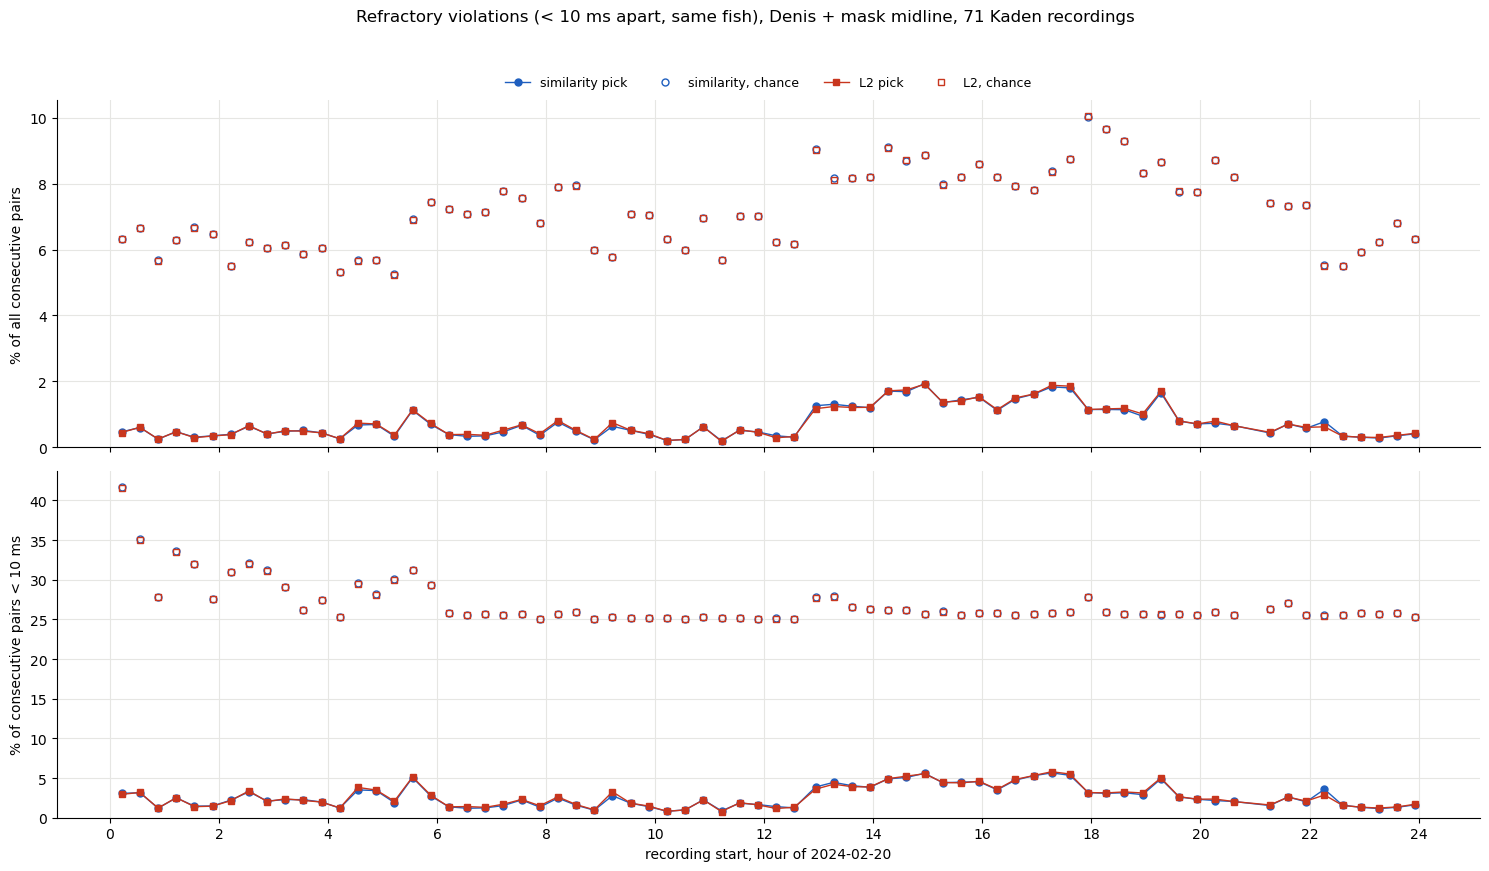

In [10]:
plot_day(10.0, 'refractory_violations_per_recording_10ms.png')

## 7. Per-pair table for time and space (similarity pick, < 6 ms)

One row per valid consecutive pair (both EODs assigned), taken at the later EOD:
- **time of day**: the recording's start (folder name) + the EOD's `Time`;
- **close**: less than 6 ms after the previous EOD; **violation**: close and both EODs given to the same fish;
- **position of the later EOD's fish** (for a violation, the fish that violates): the centre of its mask midline (point 51 of 101)
  in the EOD's video frame (`midlines_by_frame.npz`);
- **distance to the nearest wall** and **to the nearest corner**: from that point to the four wall lines of the February tank outline
  (`data/electrodes/tank_outline_updated_2-fish.csv`, the same camera and electrode layout; 2 cm cut-out at the top left);
- **distance to the nearest other fish**: smallest distance between its midline and another fish's (21 points each).

Pixels → cm: 14.2 px/cm (the 60 cm tank, `compute_electric_field.PX_PER_CM`). Only the similarity pick is used here; the L2 pick
gives the same violations to within 0.01 points (section 1).

In [11]:
PICK, LIM = 'similarity', 6.0
PXCM = 14.2
OUTLINE = pd.read_csv('data/electrodes/tank_outline_updated_2-fish.csv').to_numpy()       # x, y (px), with the cut-out
CORNERS = np.array([[OUTLINE[4, 0], OUTLINE[0, 1]], OUTLINE[1], OUTLINE[2], OUTLINE[3]])  # wall-line corners TL, TR, BR, BL
ELEC = pd.read_csv('data/electrodes/electrodes_signed_px_coord_4-fish.csv')

def wall_dist(x, y):
    '''Distance (px) of points to each of the four wall lines (top, right, bottom, left).'''
    out = []
    for a, b in zip(CORNERS, np.roll(CORNERS, -1, 0)):
        d = b - a; n = np.array([-d[1], d[0]]) / np.hypot(*d)
        out.append(np.abs((x - a[0]) * n[0] + (y - a[1]) * n[1]))
    return np.stack(out, 1)

FPS = 50                                                                     # video frames per second
BIN = 2 * PXCM; ED = np.arange(0, 912 + BIN, BIN); NB = len(ED) - 1
DIST = {'wall_cm': ('nearest wall (cm)', np.r_[np.arange(0, 6, 0.5), 7, 9, 12, 16, 31]),
        'corner_cm': ('nearest corner (cm)', np.r_[0, 2, 4, 6, 8, 10, 12, 15, 20, 25, 30, 45]),
        'nearest_fish_cm': ('nearest other fish, midline to midline (cm)', np.r_[0, 0.5, 1, 1.5, 2, 3, 4, 5, 7, 10, 15, 20, 30, 60])}
OCC = {k: np.zeros((4, NB, NB)) for k in ('all', 'near5', 'far5')}           # frames per fish and 2 cm bin
OCC1D = {name: np.zeros(len(edges) - 1) for name, (_, edges) in DIST.items()} # frames per distance bin (all fish)
NEOD = {}                                                                     # all detected EODs per minute of each video

def pair_table(t):
    d = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv', usecols=['Frame', 'Time', PICKS[PICK]], keep_default_na=False)
    k = d[PICKS[PICK]].map({f: i for i, f in enumerate(FISH)}).fillna(-1).astype(int).to_numpy()
    T = d.Time.to_numpy(); dt = np.diff(T) * 1000
    i = np.flatnonzero((k[1:] >= 0) & (k[:-1] >= 0)) + 1                      # later EOD of each valid pair
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); frames = z['frames']; M = z['mids'] * (912 - 1)   # (row, col) px
    j = np.searchsorted(frames, d.Frame.to_numpy()[i]); assert np.all(frames[j] == d.Frame.to_numpy()[i]), t
    f = k[i]; c = M[j, f, 50]                                                  # midline centre (row, col)
    S = M[:, :, ::5]                                                           # 21 points per midline
    nn = np.full((len(frames), 4), np.inf)
    for a in range(4):
        for b in range(a + 1, 4):
            dd = np.sqrt(((S[:, a, :, None] - S[:, b, None]) ** 2).sum(-1)).min((1, 2))
            nn[:, a] = np.fmin(nn[:, a], dd); nn[:, b] = np.fmin(nn[:, b], dd)
    # time spent: every frame with a midline of the fish (the frames of the midline file = frames with an EOD), 1 / FPS s each
    ok = np.isfinite(M[:, :, 50, 0])
    for fi in range(4):
        sel = ok[:, fi]; yy, xx = M[sel, fi, 50, 0], M[sel, fi, 50, 1]; near = nn[sel, fi] <= 5 * PXCM
        OCC['all'][fi] += np.histogram2d(yy, xx, bins=[ED, ED])[0]
        OCC['near5'][fi] += np.histogram2d(yy[near], xx[near], bins=[ED, ED])[0]
        OCC['far5'][fi] += np.histogram2d(yy[~near], xx[~near], bins=[ED, ED])[0]
        vals = {'wall_cm': wall_dist(xx, yy).min(1) / PXCM,
                'corner_cm': np.hypot(xx[:, None] - CORNERS[:, 0], yy[:, None] - CORNERS[:, 1]).min(1) / PXCM,
                'nearest_fish_cm': nn[sel, fi] / PXCM}
        for name, (_, edges) in DIST.items(): OCC1D[name] += np.histogram(vals[name], edges)[0]
    NEOD[t] = np.bincount(np.clip(T // 60, 0, 19).astype(int), minlength=20)
    x, y = c[:, 1], c[:, 0]
    close = dt[i - 1] < LIM
    return pd.DataFrame({'recording': t, 'tod_h': START[t] + T[i] / 3600, 'minute': np.clip(T[i] // 60, 0, 19).astype(int),
                         'fish': f, 'dt_ms': dt[i - 1].astype('float32'), 'same': k[i] == k[i - 1],
                         'close': close, 'violation': close & (k[i] == k[i - 1]),
                         'x': x.astype('float32'), 'y': y.astype('float32'),
                         'wall_cm': (wall_dist(x, y).min(1) / PXCM).astype('float32'),
                         'corner_cm': (np.hypot(x[:, None] - CORNERS[:, 0], y[:, None] - CORNERS[:, 1]).min(1) / PXCM).astype('float32'),
                         'nearest_fish_cm': (nn[j, f] / PXCM).astype('float32')})

START = {t: hours(t) for t in RECS}
PT = pd.concat([pair_table(t) for t in RECS], ignore_index=True)
chk = R[(R.pick == PICK) & (R.limit_ms == LIM)].violations.sum()
assert PT.violation.sum() == chk, (PT.violation.sum(), chk)
print(f'{len(PT):,} valid pairs, {PT.close.sum():,} close, {PT.violation.sum():,} violations (matches section 1)')
print(f"time sampled: {OCC['all'].sum() / FPS / 3600:.1f} fish-hours in frames with an EOD "
      f"(of {4 * len(RECS) * 20 / 60:.1f} fish-hours of video)")
print('fish centre outside the tank outline:', f"{100 * np.mean((PT.x < CORNERS[:, 0].min()) | (PT.x > CORNERS[:, 0].max()) | (PT.y < CORNERS[:, 1].min()) | (PT.y > CORNERS[:, 1].max())):.3f} %")

def wilson(k, n, z=1.96):
    p = k / np.maximum(n, 1); den = 1 + z ** 2 / n; c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h

3,487,983 valid pairs, 557,674 close, 15,798 violations (matches section 1)
time sampled: 58.2 fish-hours in frames with an EOD (of 94.7 fish-hours of video)
fish centre outside the tank outline: 0.009 %


## 8. Violations against the time of day

**Across the day.** 1-minute bins inside every 20-minute video, each video drawn as its own segment (gaps between videos stay empty).
- **top**: violations per 1000 detected EODs in the bin (every EOD of the table, assigned or not);
- **middle**: observed / chance in the bin. Chance = close pairs × Σ p_f², with p_f the fish shares among the bin's assigned EODs
  (the expectation under shuffled labels); 1 would mean the timing carries no information;
- **third**: detected EODs per minute, the normalising count of the top panel;
- **bottom**: each fish's share of the assigned EODs.

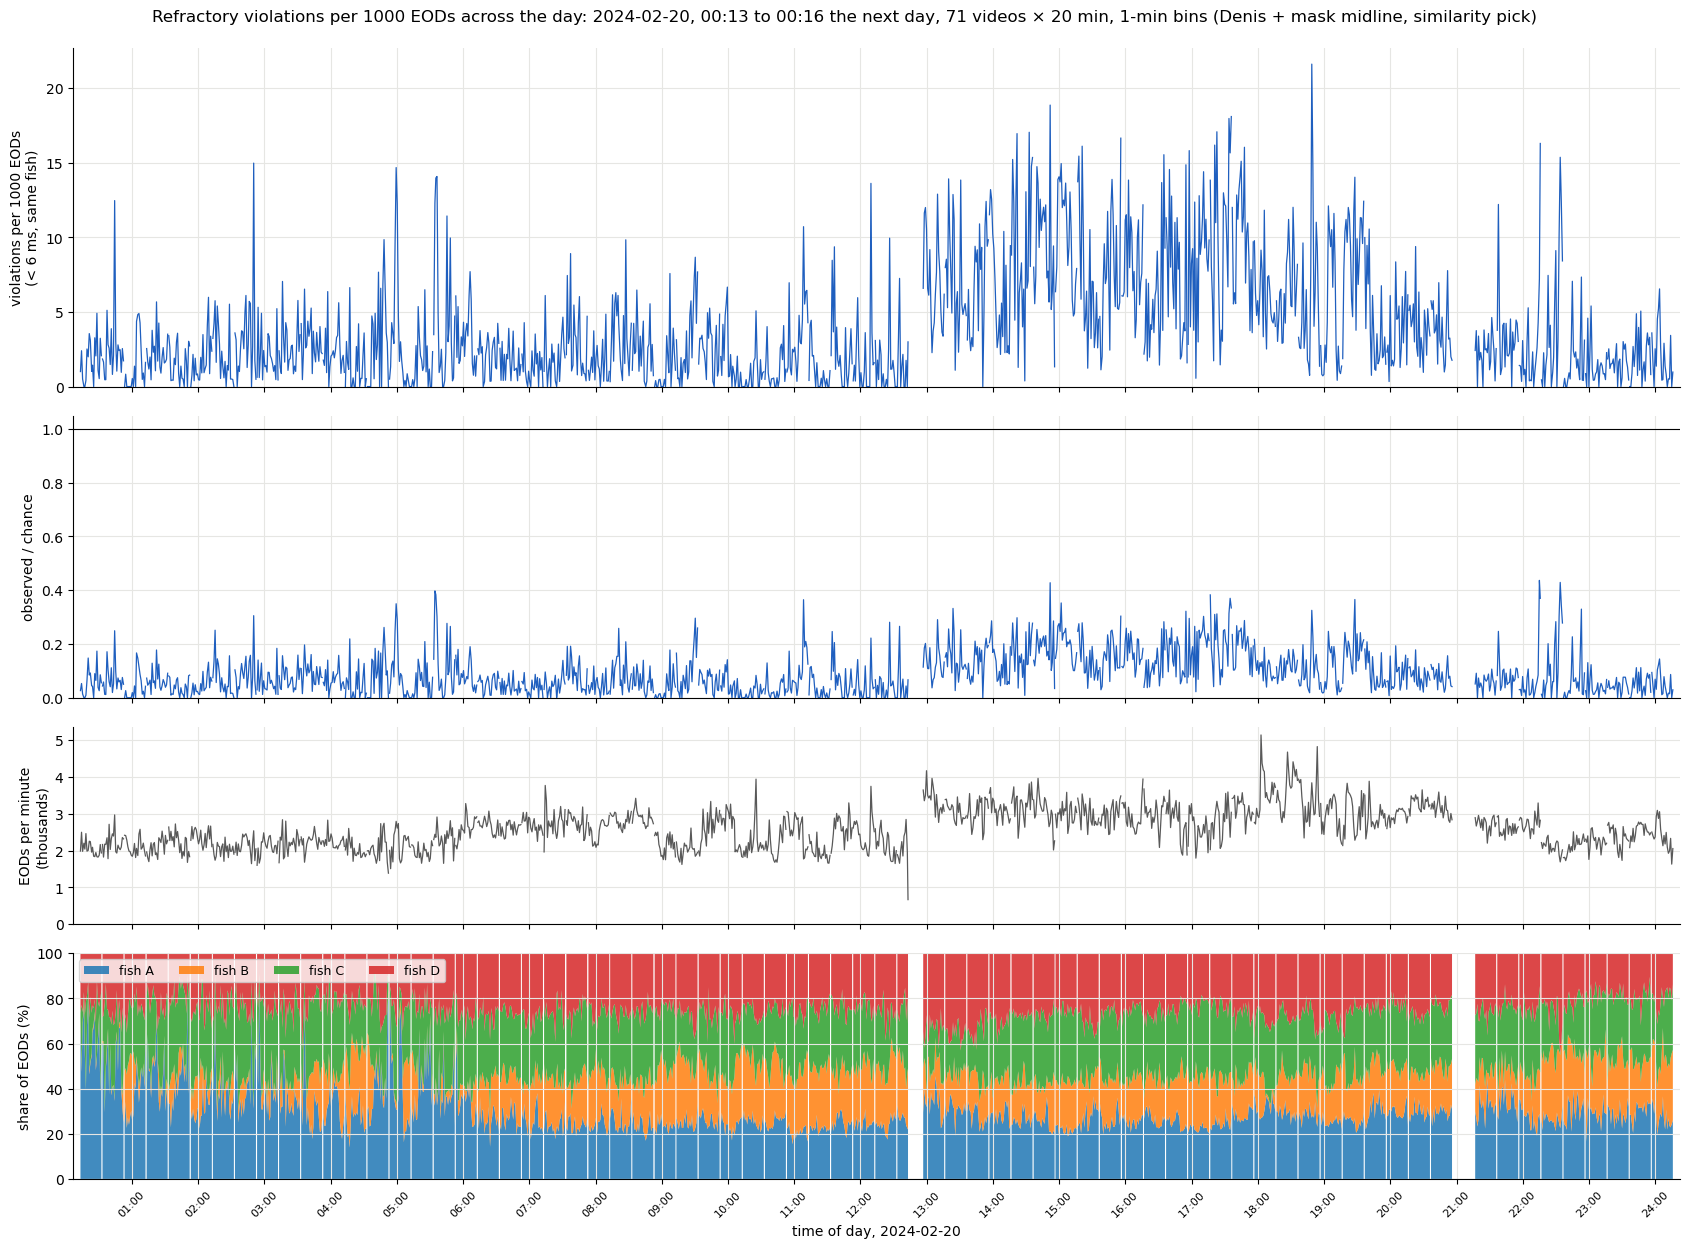

In [12]:
B = PT.groupby(['recording', 'minute']).agg(tod_h=('tod_h', 'mean'), pairs=('close', 'size'), close=('close', 'sum'),
                                            viol=('violation', 'sum'))
SH = PT.groupby(['recording', 'minute']).fish.value_counts(normalize=True).unstack(fill_value=0).reindex(columns=range(4), fill_value=0)
B['chance'] = B.close * (SH ** 2).sum(1)
B['EODs'] = [NEOD[t][m] for t, m in B.index]
B['per 1000 EODs'] = 1000 * B.viol / B.EODs
B['observed / chance'] = B.viol / B.chance
B[[f'share {f}' for f in FISH]] = 100 * SH.to_numpy()
B.to_csv(f'{OUT}/violations_per_minute.csv')

def hhmm(h): h = h % 24; return f'{int(h):02d}:{int(round(h % 1 * 60)) % 60:02d}'
t0, t1 = min(START.values()), max(START.values()) + 20 / 60
SPAN = f'{hhmm(t0)} to {hhmm(t1)}' + (' the next day' if t1 >= 24 else '')
fig, axs = plt.subplots(4, 1, figsize=(17, 12.5), sharex=True, gridspec_kw=dict(height_ratios=[1.2, 1, 0.7, 0.8]))
for t in RECS:
    b = B.loc[t]
    axs[0].plot(b.tod_h, b['per 1000 EODs'], '-', color='#1F5FBF', lw=0.9)
    axs[1].plot(b.tod_h, b['observed / chance'], '-', color='#1F5FBF', lw=0.9)
    axs[2].plot(b.tod_h, b.EODs / 1000, '-', color='0.35', lw=0.9)
    axs[3].stackplot(b.tod_h, *[b[f'share {f}'] for f in FISH], colors=[COLORS[f] for f in FISH],
                     labels=[f'fish {f}' for f in FISH] if t == RECS[0] else ['_nolegend_'] * 4, alpha=0.85)
axs[0].set_ylabel('violations per 1000 EODs\n(< 6 ms, same fish)'); axs[0].set_ylim(0, None)
axs[2].set_ylabel('EODs per minute\n(thousands)'); axs[2].set_ylim(0, None)
axs[1].set_ylabel('observed / chance'); axs[1].axhline(1, color='k', lw=0.8); axs[1].set_ylim(0, None)
axs[3].set_ylabel('share of EODs (%)'); axs[3].set_ylim(0, 100); axs[3].legend(ncol=4, loc='upper left', fontsize=9, frameon=True)
axs[3].set_xticks(range(0, 25, 1)); axs[3].set_xticklabels([f'{h:02d}:00' for h in range(25)], rotation=45, fontsize=8)
axs[3].set_xlabel('time of day, 2024-02-20'); axs[3].set_xlim(t0 - 0.1, t1 + 0.1)
fig.suptitle(f'Refractory violations per 1000 EODs across the day: 2024-02-20, {SPAN}, '
             f'{len(RECS)} videos × 20 min, 1-min bins (Denis + mask midline, similarity pick)', y=0.995)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_vs_time_of_day.png', dpi=120, bbox_inches='tight'); plt.show()

**Every video on its own.** Violations per 1000 detected EODs in 1-minute bins, one panel per video, titled with its time of day.
Grey line: the video's overall value. Same y scale in every panel.

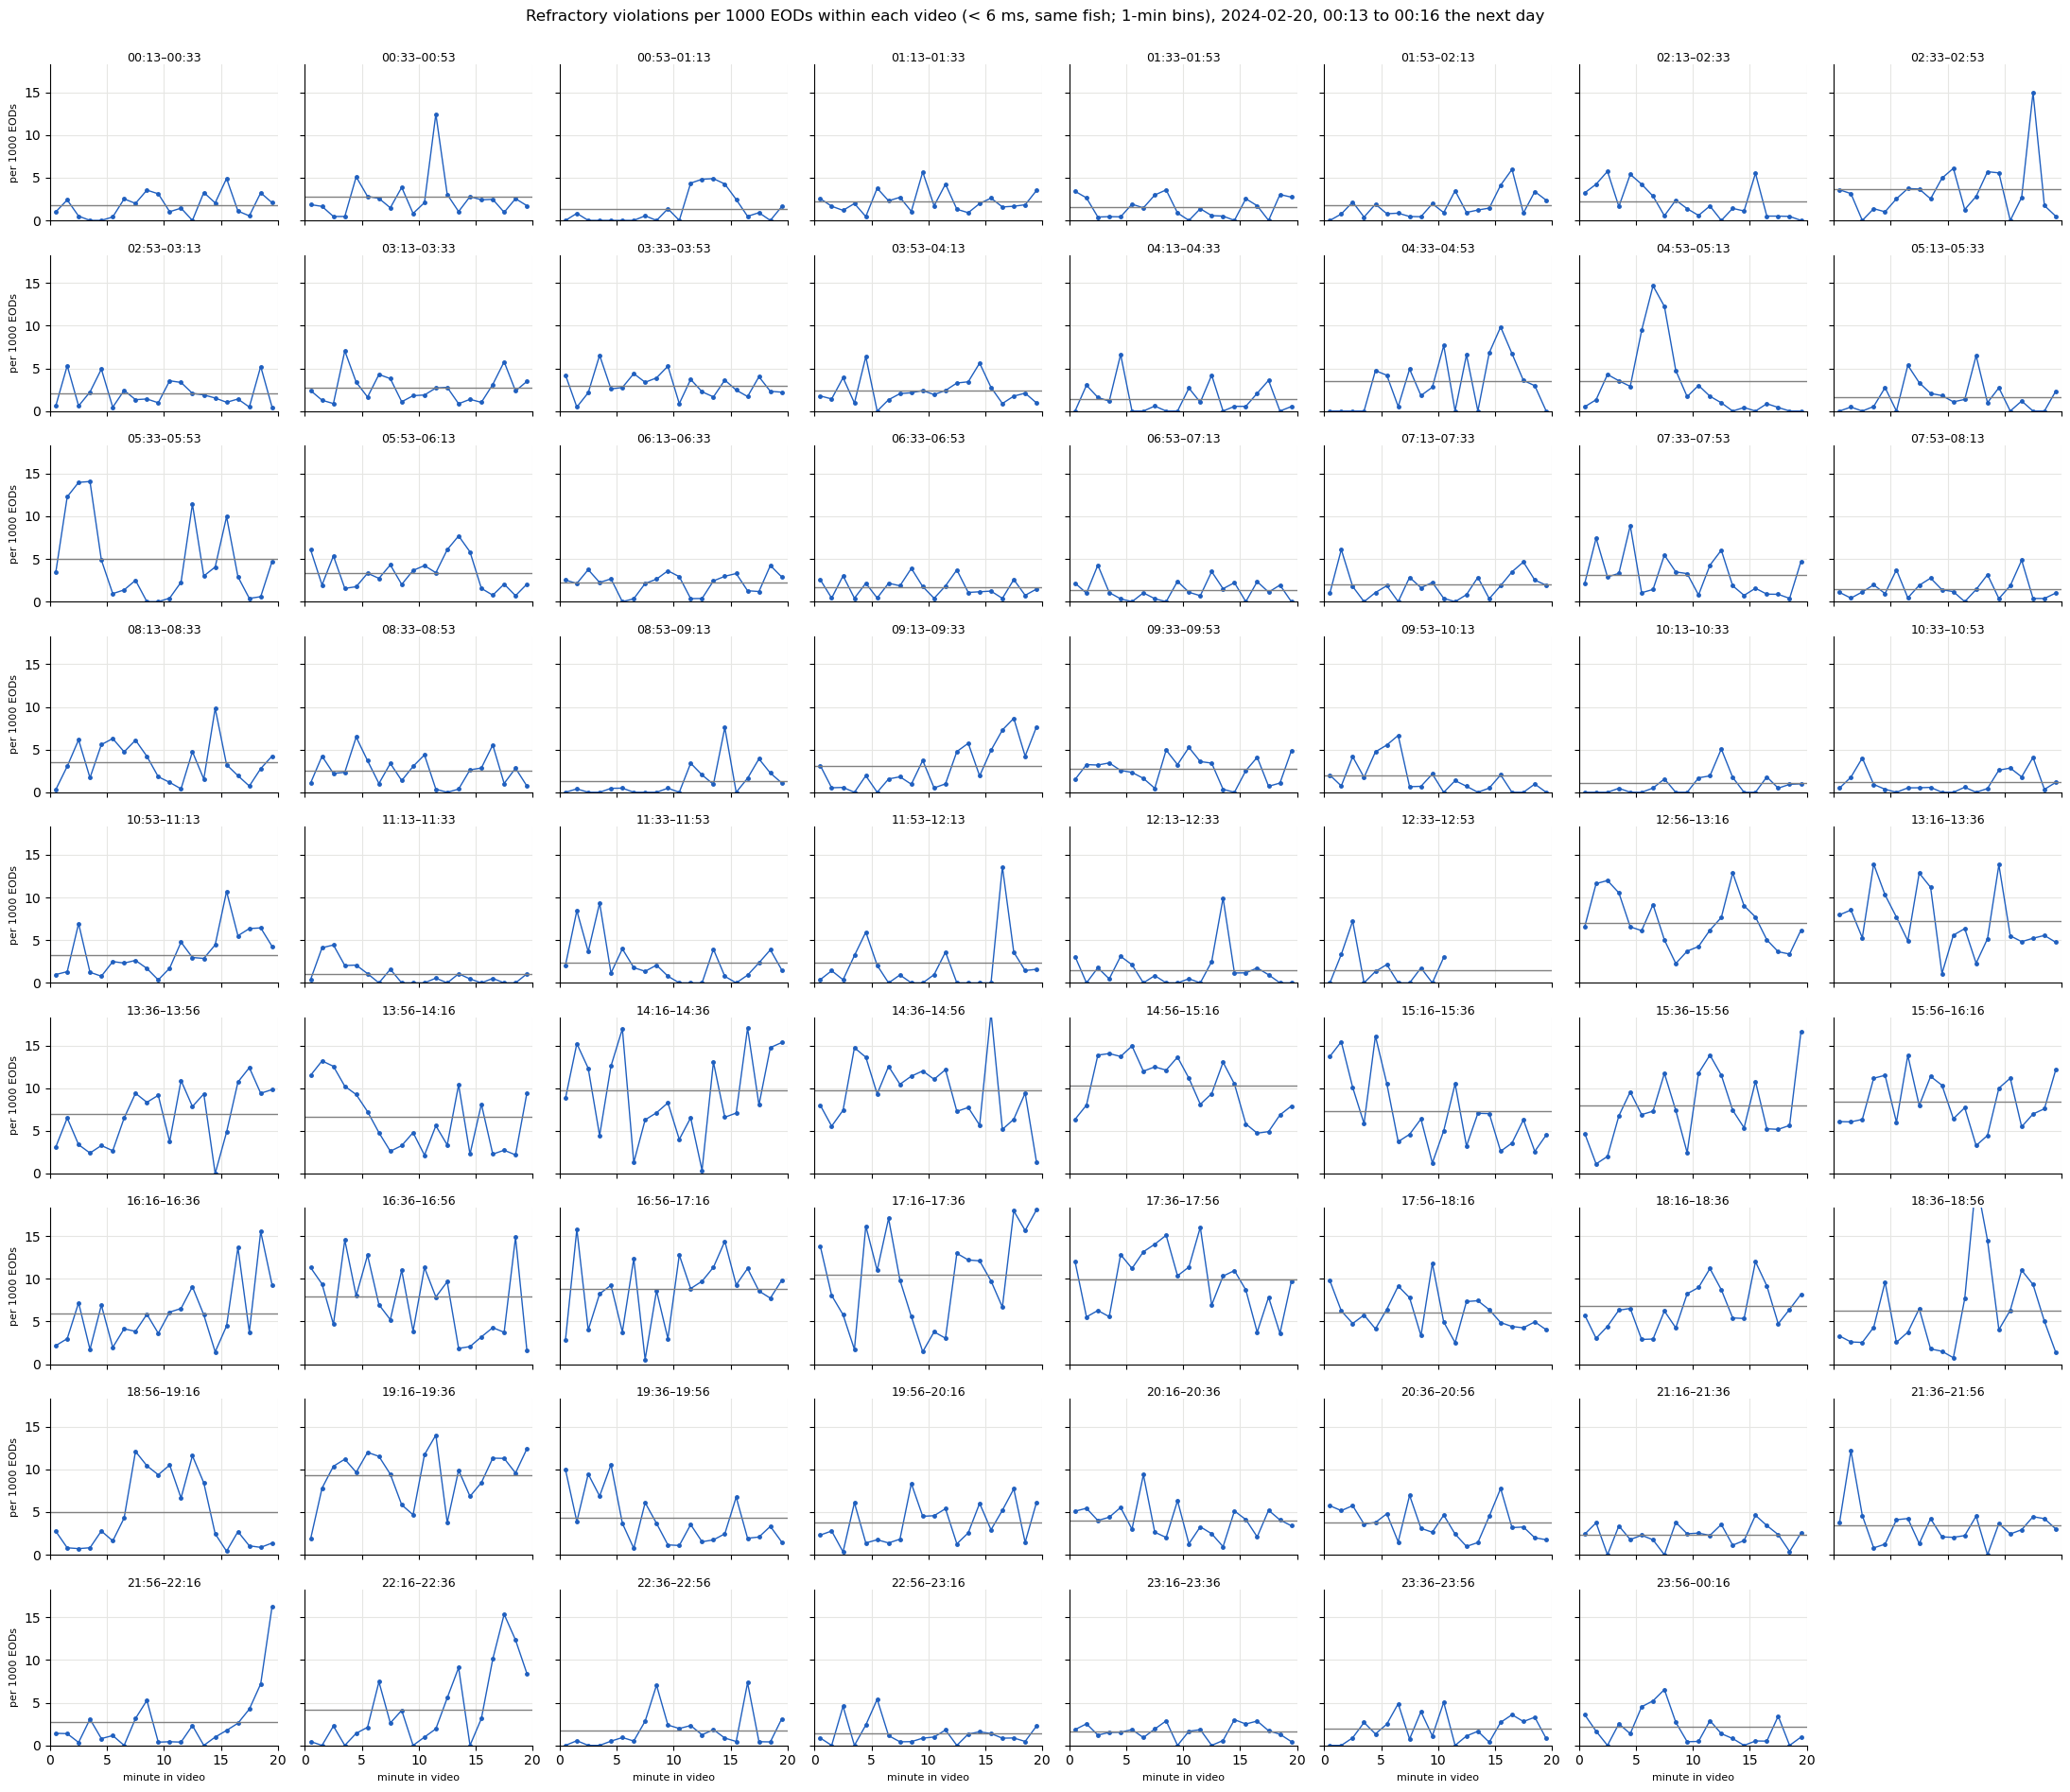

In [13]:
ncol = 8; nrow = int(np.ceil(len(RECS) / ncol))
ymax = np.nanpercentile(B['per 1000 EODs'], 99.5) * 1.1
fig, axs = plt.subplots(nrow, ncol, figsize=(22, 2.1 * nrow), sharex=True, sharey=True)
for ax, t in zip(axs.flat, RECS):
    b = B.loc[t]; s = START[t]
    ax.plot(b.index + 0.5, b['per 1000 EODs'], '-o', ms=2.5, lw=1, color='#1F5FBF')
    ax.axhline(1000 * b.viol.sum() / b.EODs.sum(), color='0.5', lw=1)
    ax.set_title(f'{hhmm(s)}–{hhmm(s + 20 / 60)}', fontsize=9, pad=2)
for ax in axs.flat[len(RECS):]: ax.set_visible(False)
for ax in axs[-1]: ax.set_xlabel('minute in video', fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel('per 1000 EODs', fontsize=8)
axs[0, 0].set_ylim(0, ymax); axs[0, 0].set_xlim(0, 20)
fig.suptitle(f'Refractory violations per 1000 EODs within each video (< 6 ms, same fish; 1-min bins), 2024-02-20, {SPAN}', y=1.0)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_per_video_small_multiples.png', dpi=110, bbox_inches='tight'); plt.show()

## 9. Violations against the position in the tank

Position = the midline centre of the later EOD's fish (for a violation, the violating fish), 2 cm bins, all 71 videos. Video
orientation (y down); tank outline in black; electrodes: + red, − blue, numbered by pair.
- **a**: where the assigned EODs are (% of all valid pairs, log colour);
- **b**: where the violations are (count);
- **c**: violations per 1000 valid pairs in the bin (bins with ≥ 300 pairs);
- **d**: % of the close pairs (< 6 ms) in the bin that are given to the same fish (bins with ≥ 50 close pairs). This divides out how
  often the EODs come close together at that spot.

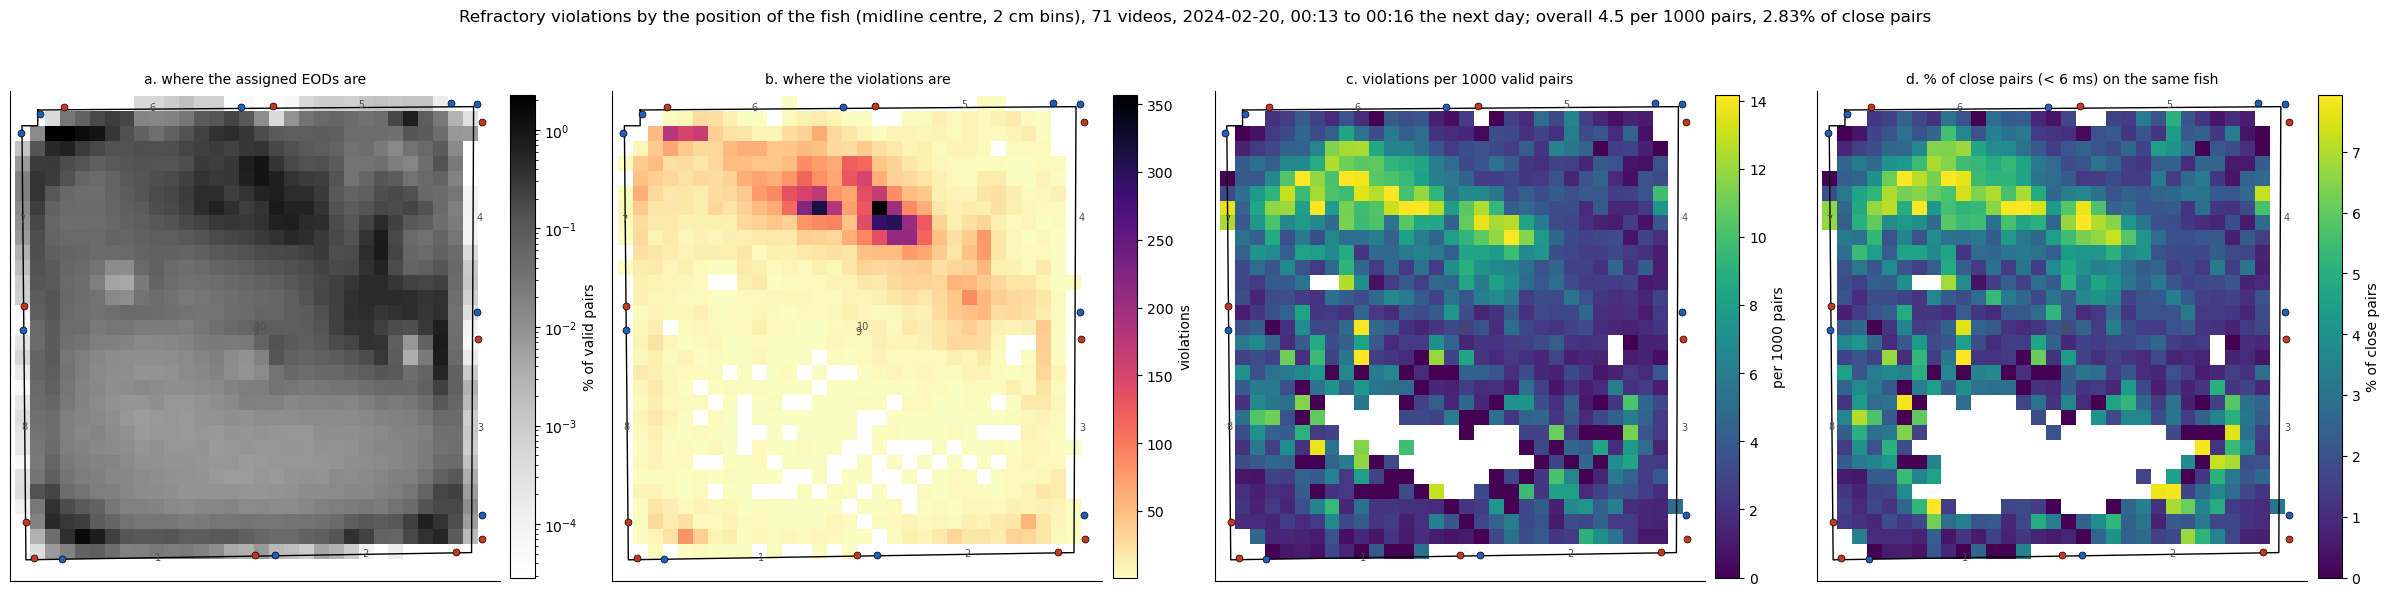

In [14]:
from matplotlib.colors import LogNorm
H = lambda w=None, sel=slice(None): np.histogram2d(PT.y[sel], PT.x[sel], bins=[ED, ED], weights=w)[0]
n_all, n_close, n_viol = H(), H(sel=PT.close.to_numpy()), H(sel=PT.violation.to_numpy())

def tank(ax):
    ax.plot(*np.r_[OUTLINE, OUTLINE[:1]].T, color='k', lw=1)
    for _, e in ELEC.iterrows():
        for x, y, pol in [(e.x1, e.y1, e.pol1), (e.x2, e.y2, e.pol2)]:
            ax.plot(x, y, 'o', ms=5, color='#C8361E' if '+' in str(pol) else '#1F5FBF', mec='k', mew=0.5)
        ax.text((e.x1 + e.x2) / 2, (e.y1 + e.y2) / 2, str(e.pair), fontsize=7, ha='center', va='center', color='0.3')
    ax.set_xlim(-10, 922); ax.set_ylim(922, -10); ax.set_aspect('equal'); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])

def show(ax, img, title, label, **kw):
    im = ax.imshow(img, extent=[ED[0], ED[-1], ED[-1], ED[0]], origin='upper', interpolation='nearest', **kw)
    tank(ax); ax.set_title(title, fontsize=10); plt.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label=label)

with np.errstate(invalid='ignore', divide='ignore'):
    rate = np.where(n_all >= 300, 1000 * n_viol / n_all, np.nan)
    frac = np.where(n_close >= 50, 100 * n_viol / n_close, np.nan)
fig, axs = plt.subplots(1, 4, figsize=(24, 6))
show(axs[0], np.where(n_all > 0, 100 * n_all / n_all.sum(), np.nan), 'a. where the assigned EODs are', '% of valid pairs',
     cmap='Greys', norm=LogNorm())
show(axs[1], np.where(n_viol > 0, n_viol, np.nan), 'b. where the violations are', 'violations', cmap='magma_r')
show(axs[2], rate, 'c. violations per 1000 valid pairs', 'per 1000 pairs', cmap='viridis',
     vmin=0, vmax=np.nanpercentile(rate, 99))
show(axs[3], frac, 'd. % of close pairs (< 6 ms) on the same fish', '% of close pairs', cmap='viridis',
     vmin=0, vmax=np.nanpercentile(frac, 99))
fig.suptitle(f'Refractory violations by the position of the fish (midline centre, 2 cm bins), 71 videos, 2024-02-20, '
             f'{SPAN}; overall {1000 * n_viol.sum() / n_all.sum():.1f} per 1000 pairs, '
             f'{100 * n_viol.sum() / n_close.sum():.2f}% of close pairs', y=1.02)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_vs_position_maps.png', dpi=120, bbox_inches='tight'); plt.show()

**Is the hot spot a place, or fish close together?** Same map as c, split by whether another fish is within 5 cm of the fish
(midline to midline), and the share of pairs with another fish that close in each bin.

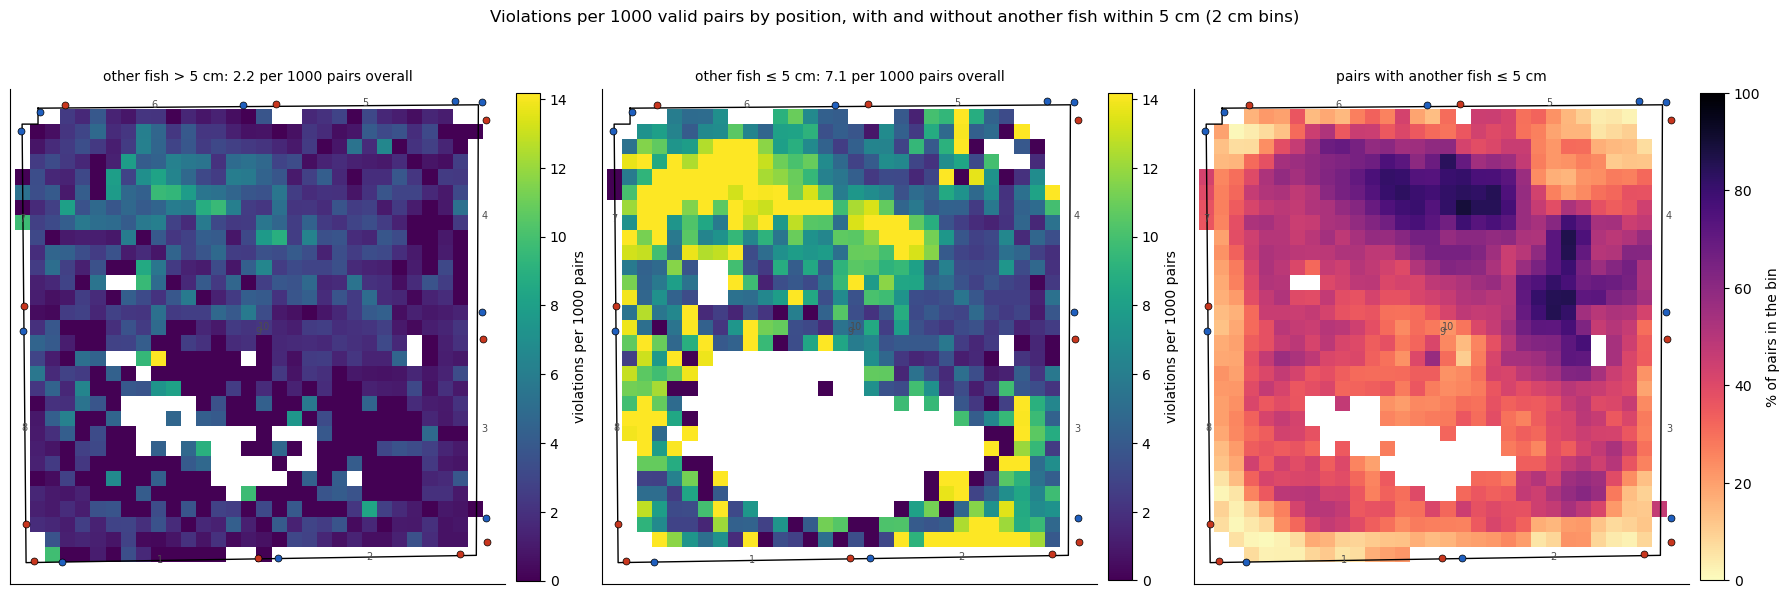

In [15]:
near5 = (PT.nearest_fish_cm <= 5).to_numpy()
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
with np.errstate(invalid='ignore', divide='ignore'):
    for ax, sel, lab in [(axs[0], ~near5, 'other fish > 5 cm'), (axs[1], near5, 'other fish ≤ 5 cm')]:
        na, nv = H(sel=sel), H(sel=sel & PT.violation.to_numpy())
        show(ax, np.where(na >= 200, 1000 * nv / na, np.nan), f'{lab}: {1000 * nv.sum() / na.sum():.1f} per 1000 pairs overall',
             'violations per 1000 pairs', cmap='viridis', vmin=0, vmax=np.nanpercentile(rate, 99))
    show(axs[2], np.where(n_all >= 300, 100 * H(sel=near5) / n_all, np.nan), 'pairs with another fish ≤ 5 cm',
         '% of pairs in the bin', cmap='magma_r', vmin=0, vmax=100)
fig.suptitle('Violations per 1000 valid pairs by position, with and without another fish within 5 cm (2 cm bins)', y=1.02)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_vs_position_near_other_fish.png', dpi=120, bbox_inches='tight'); plt.show()

**Per fish**: violations per 1000 valid pairs whose later EOD is that fish's (bins with ≥ 150 pairs of the fish).

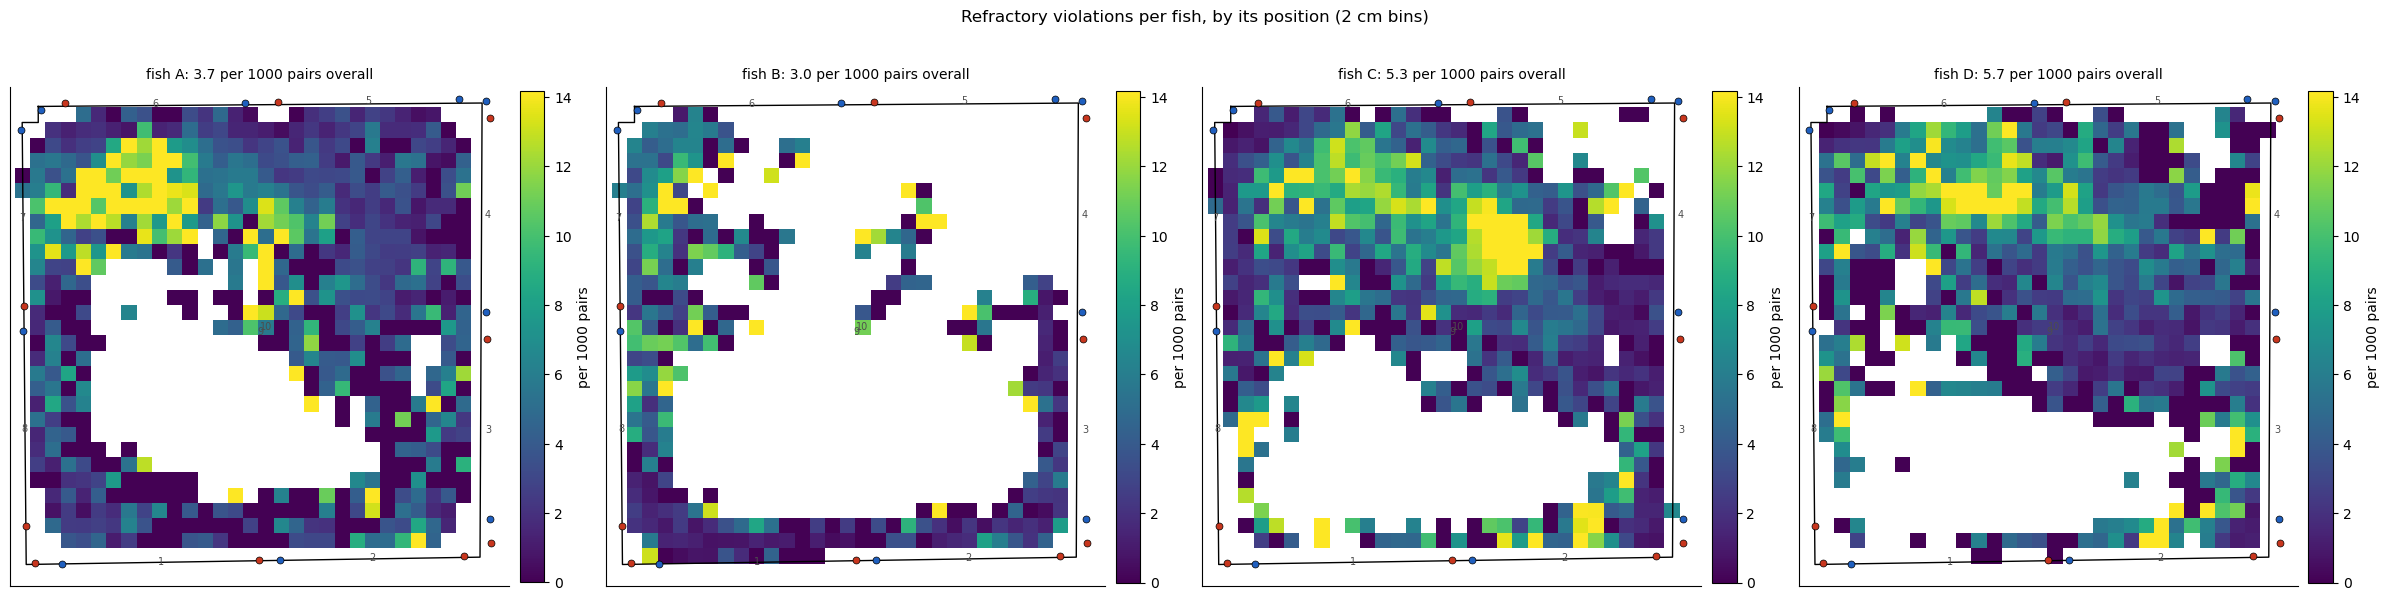

In [16]:
fig, axs = plt.subplots(1, 4, figsize=(24, 6))
for ax, (fi, f) in zip(axs, enumerate(FISH)):
    sel = (PT.fish == fi).to_numpy(); na, nv = H(sel=sel), H(sel=sel & PT.violation.to_numpy())
    with np.errstate(invalid='ignore', divide='ignore'):
        r = np.where(na >= 150, 1000 * nv / na, np.nan)
    show(ax, r, f'fish {f}: {1000 * nv.sum() / na.sum():.1f} per 1000 pairs overall', 'per 1000 pairs', cmap='viridis',
         vmin=0, vmax=np.nanpercentile(rate, 99))
fig.suptitle('Refractory violations per fish, by its position (2 cm bins)', y=1.02)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_vs_position_per_fish.png', dpi=120, bbox_inches='tight'); plt.show()

**Walls, corners and other fish.** Rate against the distance of the fish to the nearest wall, to the nearest corner, and to the
nearest other fish (equal-width bins; 95% Wilson intervals). Top: violations per 1000 valid pairs. Bottom: % of close pairs on the
same fish. Dashed: overall.

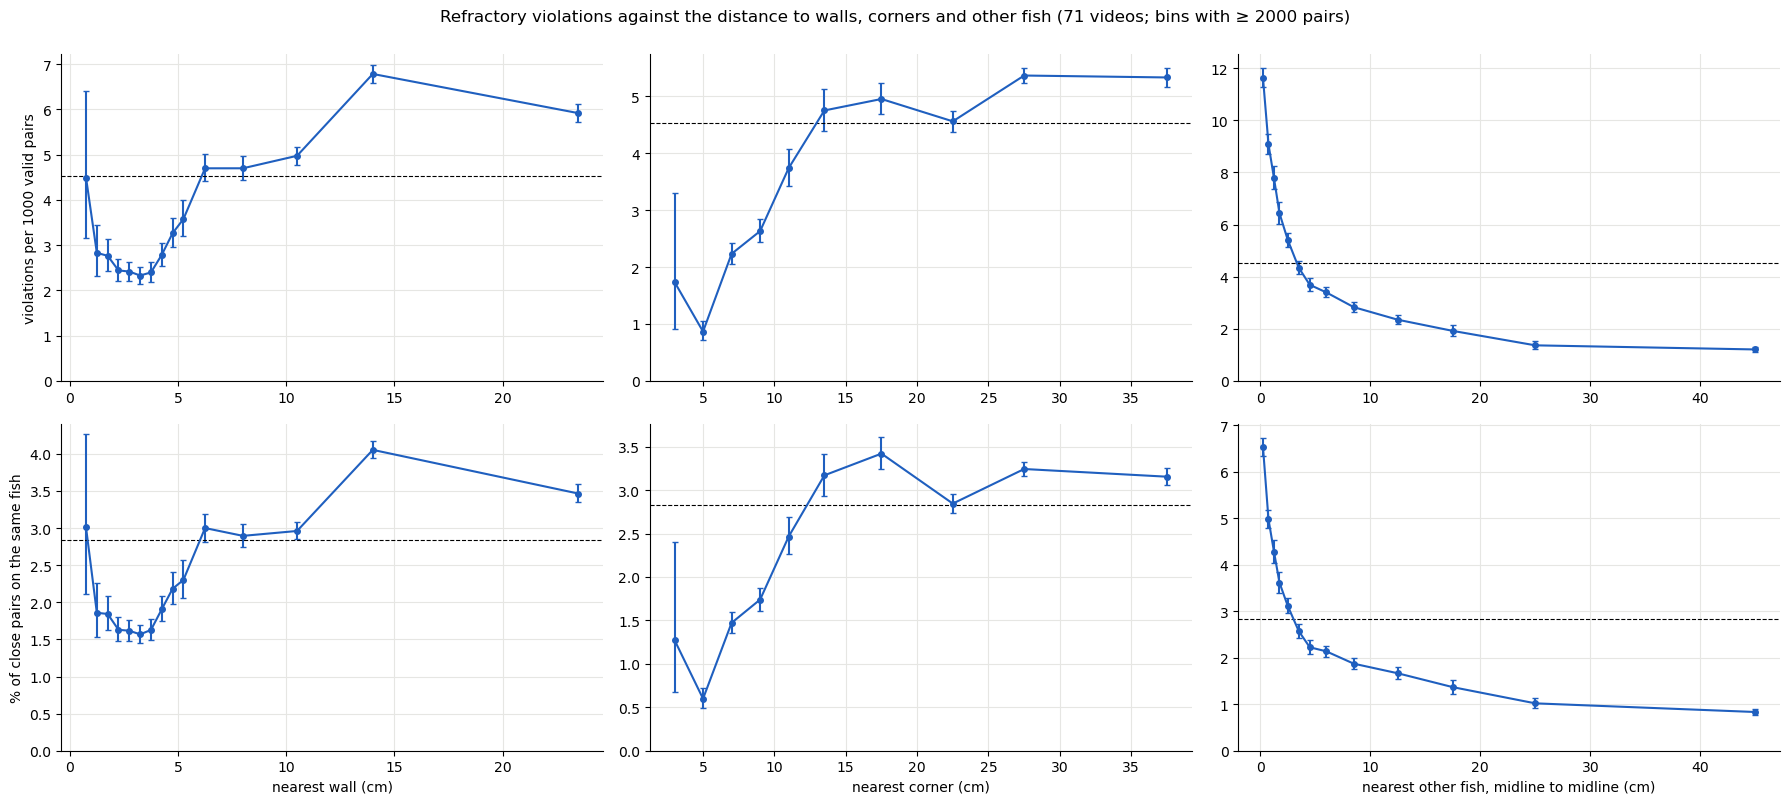

In [17]:
fig, axs = plt.subplots(2, 3, figsize=(18, 8))
rows = []
for c, (name, (col, edges)) in enumerate(DIST.items()):
    g = PT.groupby(pd.cut(PT[name], edges), observed=True).agg(pairs=('close', 'size'), close=('close', 'sum'), viol=('violation', 'sum'))
    g = g[g.pairs >= 2000]                                                     # drop near-empty bins (e.g. < 2 cm from a corner)
    x = np.array([iv.mid for iv in g.index])
    for r, (num, den, sc, lab) in enumerate([(g.viol, g.pairs, 1000, 'violations per 1000 valid pairs'),
                                             (g.viol, g.close, 100, '% of close pairs on the same fish')]):
        lo, hi = wilson(num.to_numpy(), den.to_numpy())
        axs[r, c].errorbar(x, sc * num / den, yerr=[sc * num / den - sc * lo, sc * hi - sc * num / den], fmt='-o', ms=4,
                           color='#1F5FBF', capsize=2)
        axs[r, c].axhline(sc * PT.violation.sum() / (len(PT) if r == 0 else PT.close.sum()), color='k', ls='--', lw=0.8)
        axs[r, 0].set_ylabel(lab)
    axs[1, c].set_xlabel(col)
    rows.append(g.assign(variable=name, **{'per 1000 pairs': 1000 * g.viol / g.pairs, '% of close pairs': 100 * g.viol / g.close}))
for ax in axs.flat: ax.set_ylim(0, None)
fig.suptitle('Refractory violations against the distance to walls, corners and other fish (71 videos; bins with ≥ 2000 pairs)', y=1.0)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_vs_distance_wall_corner_fish.png', dpi=120, bbox_inches='tight'); plt.show()
pd.concat(rows).to_csv(f'{OUT}/violations_vs_distance.csv')

**Zones, with and without another fish close by.**
- Zones: **corner** = within 8 cm of a corner; **wall** = within 3 cm of a wall and not a corner; **open water** = the rest.
- Each zone is split by whether another fish is within 3 cm, since fish near each other are the hard case for any assignment.

In [18]:
zone = np.select([PT.corner_cm <= 8, PT.wall_cm <= 3], ['corner', 'wall'], 'open water')
near = np.where(PT.nearest_fish_cm <= 3, 'other fish ≤ 3 cm', 'other fish > 3 cm')
Z = PT.assign(zone=zone, near=near).groupby(['zone', 'near']).agg(pairs=('close', 'size'), close=('close', 'sum'), viol=('violation', 'sum'))
Z = pd.concat([Z, PT.assign(zone=zone).groupby('zone').agg(pairs=('close', 'size'), close=('close', 'sum'), viol=('violation', 'sum'))
               .assign(near='all').set_index('near', append=True)]).sort_index()
Z['% of pairs in zone'] = 100 * Z.pairs / len(PT)
Z['per 1000 pairs'] = 1000 * Z.viol / Z.pairs
lo, hi = wilson(Z.viol.to_numpy(), Z.pairs.to_numpy()); Z['per 1000, 95% CI'] = [f'{1000 * a:.2f}–{1000 * b:.2f}' for a, b in zip(lo, hi)]
Z['% close pairs'] = 100 * Z.close / Z.pairs
Z['% of close pairs on the same fish'] = 100 * Z.viol / Z.close
Z.to_csv(f'{OUT}/violations_by_zone.csv'); Z.round(2)

pairs   close   viol  % of pairs in zone  \
zone       near                                                            
corner     all                 389535   58151    703               11.17   
           other fish > 3 cm   377399   56014    547               10.82   
           other fish ≤ 3 cm    12136    2137    156                0.35   
open water all                2709964  441035  14010               77.69   
           other fish > 3 cm  1604663  243467   4808               46.01   
           other fish ≤ 3 cm  1105301  197568   9202               31.69   
wall       all                 388484   58488   1085               11.14   
           other fish > 3 cm   349277   51725    684               10.01   
           other fish ≤ 3 cm    39207    6763    401                1.12   

                              per 1000 pairs per 1000, 95% CI  % close pairs  \
zone       near                                                                
corner     all                          1.80        1.68–1.94          14.93   
           other fish > 3 cm            1.45        1.33–1.58          14.84   
           other fish ≤ 3 cm           12.85      11.00–15.02          17.61   
open water all                          5.17        5.09–5.26          16.27   
           other fish > 3 cm            3.00        2.91–3.08          15.17   
           other fish ≤ 3 cm            8.33        8.16–8.50          17.87   
wall       all                          2.79        2.63–2.96          15.06   
           other fish > 3 cm            1.96        1.82–2.11          14.81   
           other fish ≤ 3 cm           10.23       9.28–11.27          17.25   

                              % of close pairs on the same fish  
zone       near                                                  
corner     all                                             1.21  
           other fish > 3 cm                               0.98  
           other fish ≤ 3 cm                               7.30  
open water all                                             3.18  
           other fish > 3 cm                               1.97  
           other fish ≤ 3 cm                               4.66  
wall       all                                             1.86  
           other fish > 3 cm                               1.32  
           other fish ≤ 3 cm                               5.93

## 10. Space normalised by the time spent there

Violations per **minute that a fish spends** in each place, instead of per EOD pair.
- **Time spent**: every video frame in which a fish has a midline, its midline centre counted in its 2 cm bin, 20 ms per frame (50 fps).
- The midline files hold only the frames that contain at least one EOD, so these frames are the time sample.
- **Violations**: as in section 9, counted at the position of the violating fish.

Panels:
- **a**: time spent (fish-minutes, all four fish, log colour);
- **b**: violations per fish-minute (bins with ≥ 1 fish-minute);
- **c, d**: the same, split by whether another fish is within 5 cm. The time spent is split in the same way, frame by frame.

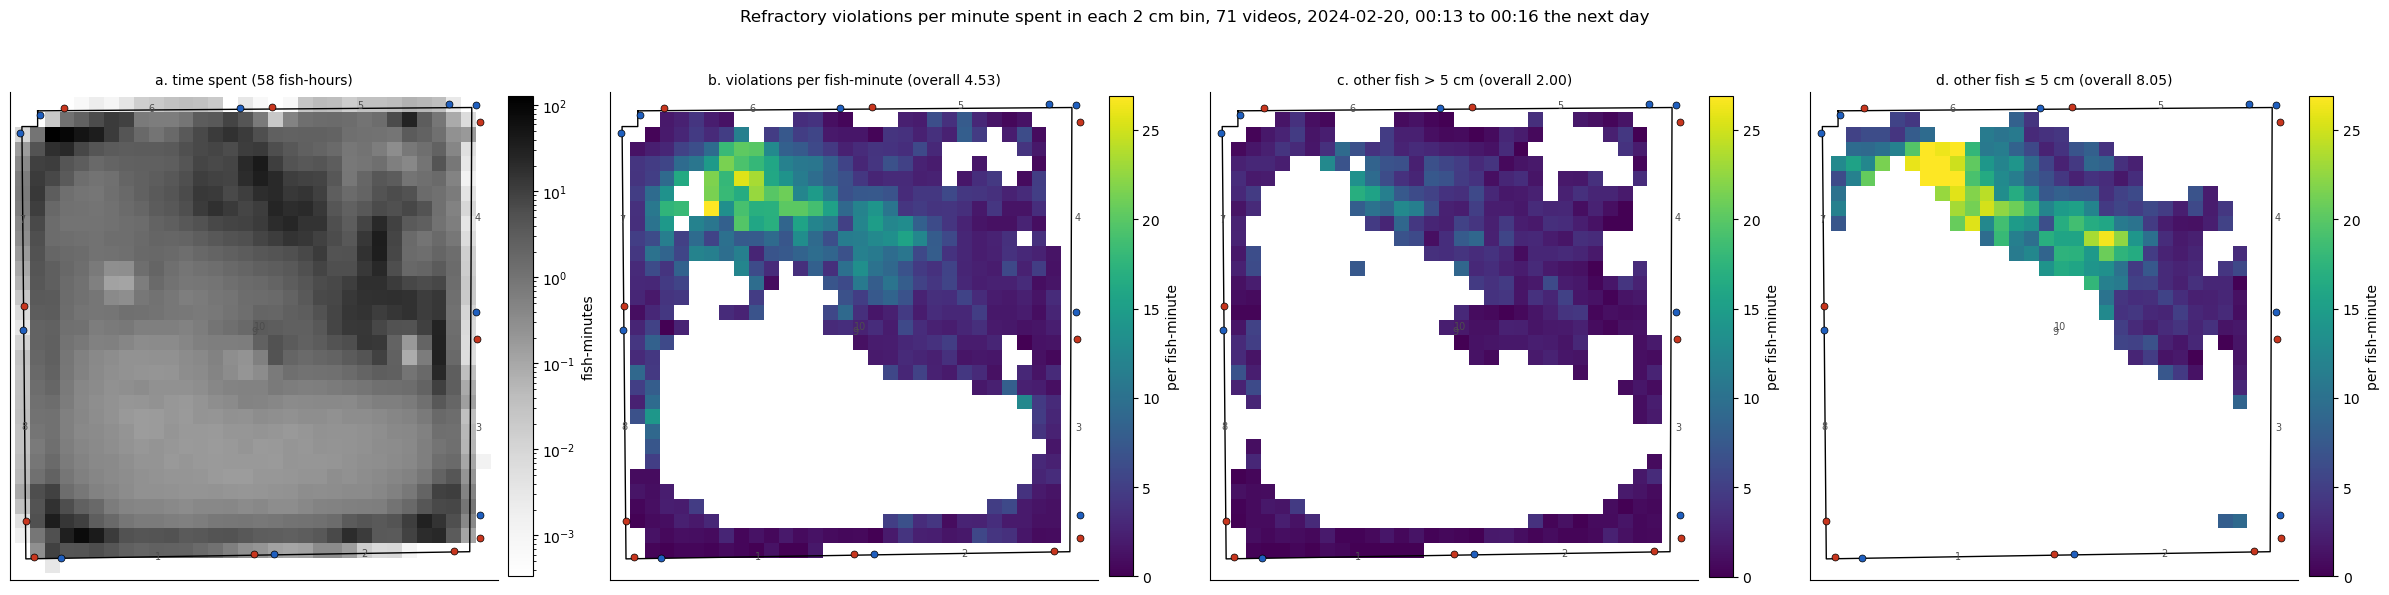

In [19]:
MIN = lambda frames: frames / FPS / 60                                          # frames -> minutes
occ, occ_far, occ_near = MIN(OCC['all'].sum(0)), MIN(OCC['far5'].sum(0)), MIN(OCC['near5'].sum(0))
viol = PT.violation.to_numpy(); n5 = (PT.nearest_fish_cm <= 5).to_numpy()
v_all, v_far, v_near = H(sel=viol), H(sel=viol & ~n5), H(sel=viol & n5)
with np.errstate(invalid='ignore', divide='ignore'):
    r_all = np.where(occ >= 1, v_all / occ, np.nan)
    r_far = np.where(occ_far >= 1, v_far / occ_far, np.nan)
    r_near = np.where(occ_near >= 1, v_near / occ_near, np.nan)
vmax = np.nanpercentile(np.r_[r_all.ravel(), r_near.ravel()], 99)
fig, axs = plt.subplots(1, 4, figsize=(24, 6))
show(axs[0], np.where(occ > 0, occ, np.nan), f'a. time spent ({occ.sum() / 60:.0f} fish-hours)', 'fish-minutes', cmap='Greys', norm=LogNorm())
show(axs[1], r_all, f'b. violations per fish-minute (overall {v_all.sum() / occ.sum():.2f})', 'per fish-minute',
     cmap='viridis', vmin=0, vmax=vmax)
show(axs[2], r_far, f'c. other fish > 5 cm (overall {v_far.sum() / occ_far.sum():.2f})', 'per fish-minute', cmap='viridis', vmin=0, vmax=vmax)
show(axs[3], r_near, f'd. other fish ≤ 5 cm (overall {v_near.sum() / occ_near.sum():.2f})', 'per fish-minute', cmap='viridis', vmin=0, vmax=vmax)
fig.suptitle(f'Refractory violations per minute spent in each 2 cm bin, 71 videos, 2024-02-20, {SPAN}', y=1.02)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_per_minute_spent_maps.png', dpi=120, bbox_inches='tight'); plt.show()
pd.DataFrame({'y_px': np.repeat((ED[:-1] + ED[1:]) / 2, NB), 'x_px': np.tile((ED[:-1] + ED[1:]) / 2, NB),
              'fish_minutes': occ.ravel(), 'violations': v_all.ravel(), 'per_fish_minute': r_all.ravel(),
              'fish_minutes_other_fish_le5cm': occ_near.ravel(), 'violations_other_fish_le5cm': v_near.ravel()}
             ).to_csv(f'{OUT}/violations_per_minute_spent_bins.csv', index=False)

**Per fish**: each fish's violations per minute it spends in the bin (bins with ≥ 0.5 fish-minutes).

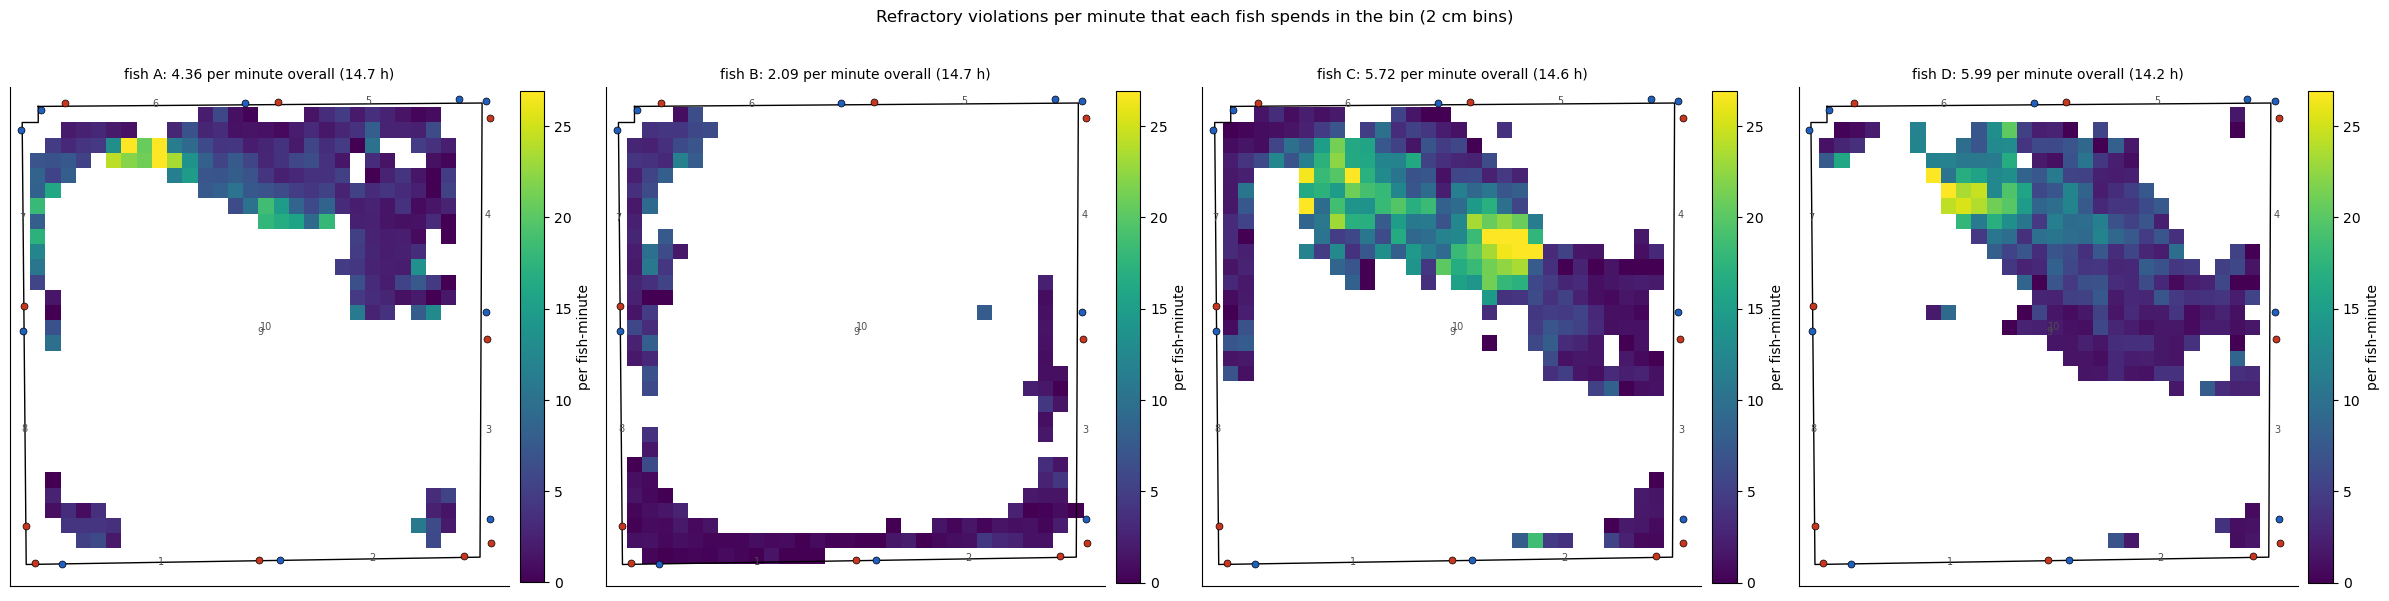

In [20]:
fig, axs = plt.subplots(1, 4, figsize=(24, 6))
for ax, (fi, f) in zip(axs, enumerate(FISH)):
    o = MIN(OCC['all'][fi]); v = H(sel=viol & (PT.fish == fi).to_numpy())
    with np.errstate(invalid='ignore', divide='ignore'):
        r = np.where(o >= 0.5, v / o, np.nan)
    show(ax, r, f'fish {f}: {v.sum() / o.sum():.2f} per minute overall ({o.sum() / 60:.1f} h)', 'per fish-minute',
         cmap='viridis', vmin=0, vmax=vmax)
fig.suptitle('Refractory violations per minute that each fish spends in the bin (2 cm bins)', y=1.02)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_per_minute_spent_per_fish.png', dpi=120, bbox_inches='tight'); plt.show()

**Walls, corners and other fish, per minute spent.** Violations per fish-minute against the distance to the nearest wall, the
nearest corner and the nearest other fish (bins with ≥ 30 fish-minutes; error bars: Poisson 95% intervals on the counts). Bottom:
the time spent at each distance. Dashed: overall.

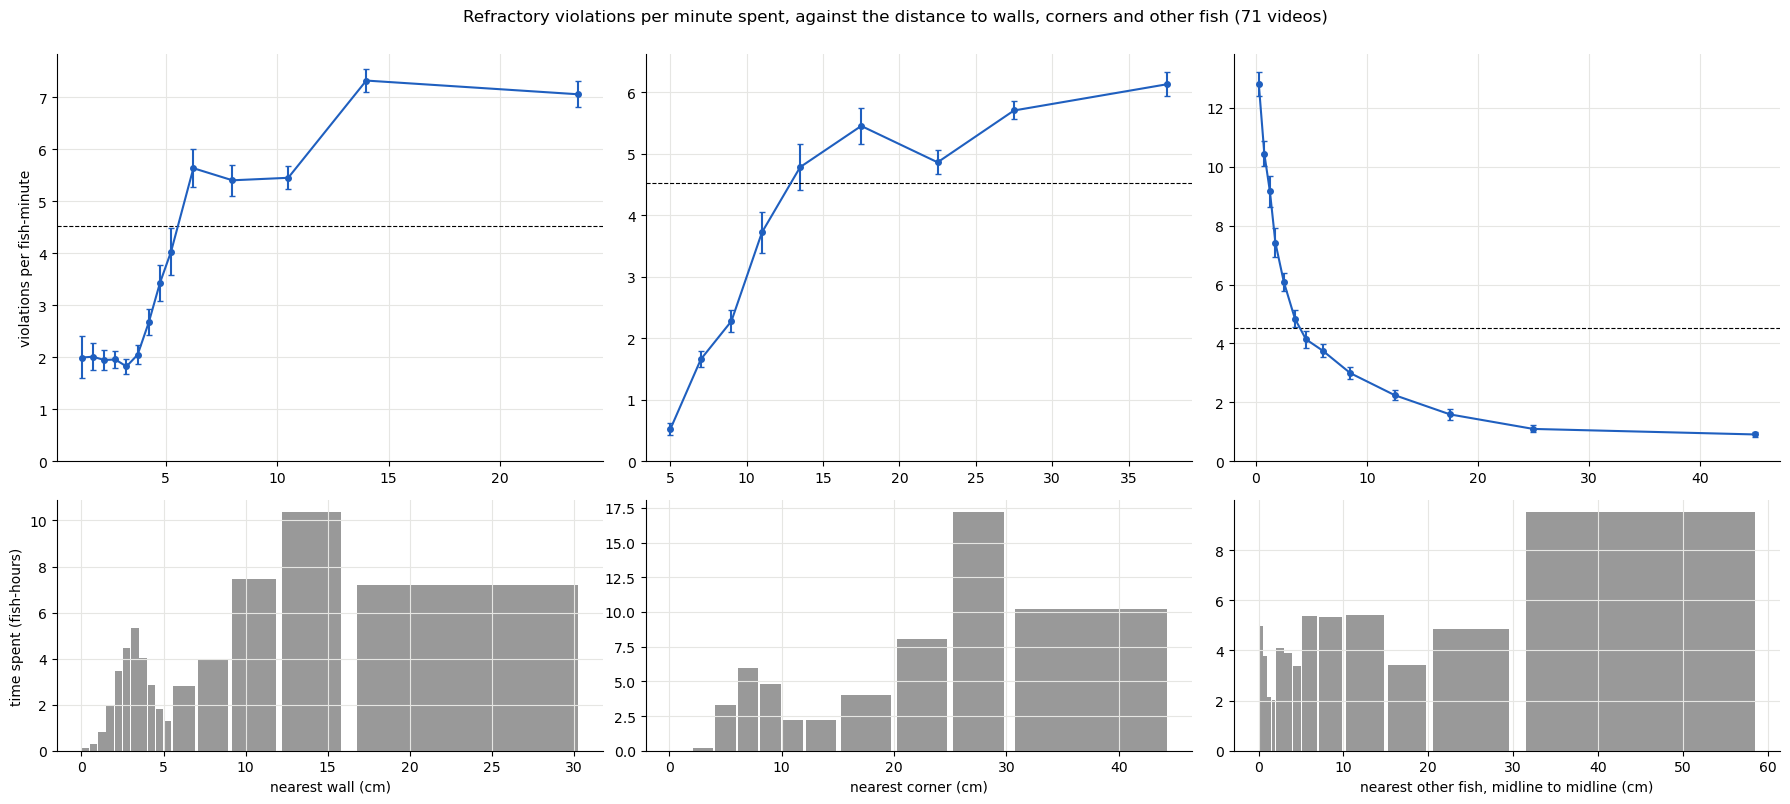

In [21]:
fig, axs = plt.subplots(2, 3, figsize=(18, 8), gridspec_kw=dict(height_ratios=[1.3, 0.8]))
rows = []; overall = PT.violation.sum() / MIN(OCC['all'].sum())
for c, (name, (col, edges)) in enumerate(DIST.items()):
    v = np.histogram(PT[name][viol], edges)[0]; o = MIN(OCC1D[name]); x = (edges[1:] + edges[:-1]) / 2
    keep = o >= 30
    r = v / np.where(o > 0, o, np.nan)
    lo = np.where(v > 0, (v - 1.96 * np.sqrt(v)) / o, 0); hi = (v + 1.96 * np.sqrt(v) + 1) / o
    axs[0, c].errorbar(x[keep], r[keep], yerr=[r[keep] - np.maximum(lo[keep], 0), hi[keep] - r[keep]], fmt='-o', ms=4,
                       color='#1F5FBF', capsize=2)
    axs[0, c].axhline(overall, color='k', ls='--', lw=0.8); axs[0, c].set_ylim(0, None)
    axs[1, c].bar(x, o / 60, width=np.diff(edges) * 0.9, color='0.6'); axs[1, c].set_xlabel(col)
    rows.append(pd.DataFrame({'variable': name, 'bin_lo': edges[:-1], 'bin_hi': edges[1:], 'violations': v,
                              'fish_minutes': o, 'per_fish_minute': r}))
axs[0, 0].set_ylabel('violations per fish-minute'); axs[1, 0].set_ylabel('time spent (fish-hours)')
fig.suptitle('Refractory violations per minute spent, against the distance to walls, corners and other fish (71 videos)', y=1.0)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_per_minute_vs_distance.png', dpi=120, bbox_inches='tight'); plt.show()
pd.concat(rows).to_csv(f'{OUT}/violations_per_minute_vs_distance.csv', index=False)

## 11. Another fish nearby (< 6.5 ms)

For every valid consecutive pair, the **emitting fish** is the fish the later EOD is assigned to (for a violation, the fish given
both EODs). **Another fish nearby** = another fish's midline within d cm of the emitting fish's midline, in the EOD's video frame
(smallest distance between the two midlines, 21 points each; section 7).
- Midlines run along the middle of the body, so the gap between the two **masks** is smaller, by about half a body width on each
  side (roughly 1–1.5 cm).
- Threshold here: **6.5 ms**. Sections 7–10 use 6 ms.

Panels:
- **a**: by distance class of the nearest other fish: violations as a % of all pairs, and the % of close pairs given to the same
  fish, against chance in that class (close pairs × Σ p_f², with the fish shares of the class);
- **b**: per video, % violations with another fish within 3 cm and with none within 3 cm; dashed lines are the medians over the 71
  videos;
- **c**: per video, the % of pairs with another fish within 3 cm.

,pairs,% of all pairs,close pairs,violations,% violations of pairs,"chance, % of pairs",% of close pairs on same fish,"chance, % of close pairs"
0–1 cm,588907.0,16.884,115834.0,6775.0,1.150,6.098,5.849,31.004
1–2 cm,289987.0,8.314,57121.0,2271.0,0.783,5.855,3.976,29.722
2–3 cm,277750.0,7.963,52589.0,1649.0,0.594,5.630,3.136,29.733
3–5 cm,488041.0,13.992,89298.0,2165.0,0.444,5.277,2.424,28.840
5–10 cm,696628.0,19.972,118211.0,2370.0,0.340,4.547,2.005,26.797
10–20 cm,480656.0,13.780,74092.0,1156.0,0.241,3.945,1.560,25.590
> 20 cm,666014.0,19.095,102785.0,914.0,0.137,4.768,0.889,30.897
another fish ≤ 3 cm,1156644.0,33.161,225544.0,10695.0,0.925,5.865,4.742,30.079
none within 3 cm,2331339.0,66.839,384386.0,6605.0,0.283,4.157,1.718,25.212


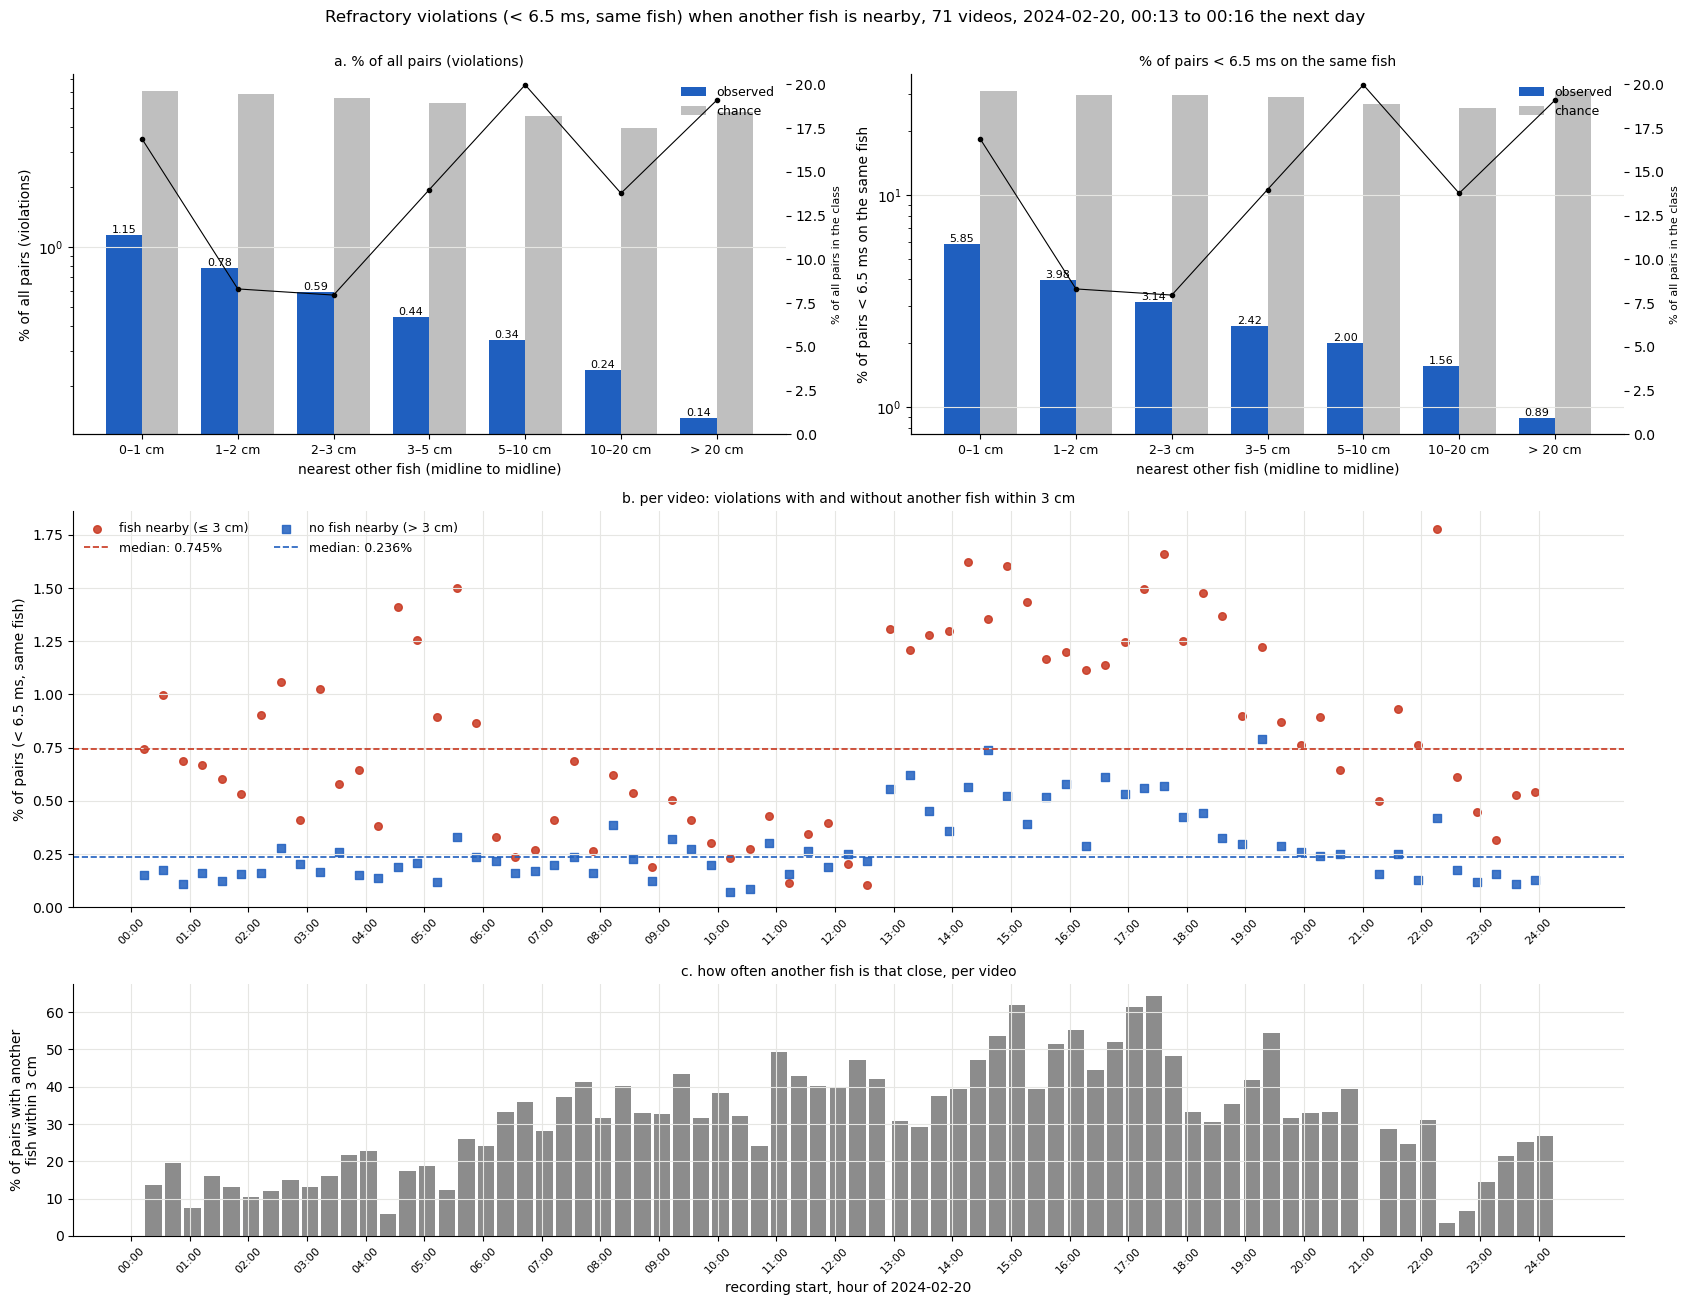

% violations, fish nearby        0.745
% violations, no fish nearby     0.236
% pairs with fish nearby        32.194
dtype: float64


correlation over videos, % violations (all) vs % pairs with a fish nearby: 0.66


In [22]:
LIM2, NEAR_CM = 6.5, 3.0
cl2 = (PT.dt_ms < LIM2).to_numpy(); v2 = cl2 & PT.same.to_numpy()
CLS = [0, 1, 2, 3, 5, 10, 20, 100]
lab = pd.cut(PT.nearest_fish_cm, CLS, right=True, labels=[f'{a}–{b} cm' if b < 100 else f'> {a} cm' for a, b in zip(CLS[:-1], CLS[1:])])

def summ(sel):
    n, c, v = sel.sum(), (sel & cl2).sum(), (sel & v2).sum()
    pf = np.bincount(PT.fish.to_numpy()[sel], minlength=4) / max(n, 1)
    return pd.Series({'pairs': n, '% of all pairs': 100 * n / len(PT), 'close pairs': c, 'violations': v,
                      '% violations of pairs': 100 * v / n, 'chance, % of pairs': 100 * c * (pf ** 2).sum() / n,
                      '% of close pairs on same fish': 100 * v / c, 'chance, % of close pairs': 100 * (pf ** 2).sum()})

NB_ = pd.DataFrame({c: summ((lab == c).to_numpy()) for c in lab.cat.categories}).T
NB_.loc[f'another fish ≤ {NEAR_CM:g} cm'] = summ((PT.nearest_fish_cm <= NEAR_CM).to_numpy())
NB_.loc[f'none within {NEAR_CM:g} cm'] = summ((PT.nearest_fish_cm > NEAR_CM).to_numpy())
NB_.to_csv(f'{OUT}/violations_another_fish_nearby_6.5ms.csv'); display(NB_.round(3))

near = (PT.nearest_fish_cm <= NEAR_CM).to_numpy()
PV = pd.DataFrame([{'recording': t, 'hour': START[t],
                    '% violations, fish nearby': 100 * (v2 & near & m).sum() / (near & m).sum(),
                    '% violations, no fish nearby': 100 * (v2 & ~near & m).sum() / (~near & m).sum(),
                    '% pairs with fish nearby': 100 * (near & m).sum() / m.sum()}
                   for t, m in ((t, (PT.recording == t).to_numpy()) for t in RECS)])
PV.to_csv(f'{OUT}/violations_another_fish_nearby_per_video_6.5ms.csv', index=False)

fig = plt.figure(figsize=(17, 13)); gs = fig.add_gridspec(3, 2, height_ratios=[1, 1.1, 0.7])
cats = list(lab.cat.categories); x = np.arange(len(cats)); w = 0.38
for j, (col, ch, ylab) in enumerate([('% violations of pairs', 'chance, % of pairs', '% of all pairs (violations)'),
                                     ('% of close pairs on same fish', 'chance, % of close pairs', f'% of pairs < {LIM2:g} ms on the same fish')]):
    ax = fig.add_subplot(gs[0, j]); t_ = NB_.loc[cats]
    ax.bar(x - w / 2, t_[col], w, color='#1F5FBF', label='observed')
    ax.bar(x + w / 2, t_[ch], w, color='0.75', label='chance')
    for xx, v in zip(x - w / 2, t_[col]): ax.text(xx, v, f'{v:.2f}', ha='center', va='bottom', fontsize=8)
    ax2 = ax.twinx(); ax2.plot(x, t_['% of all pairs'], 'k.-', lw=0.8); ax2.set_ylabel('% of all pairs in the class', fontsize=8)
    ax2.set_ylim(0, None); ax2.grid(False)
    ax.set_xticks(x); ax.set_xticklabels(cats, fontsize=9); ax.set_xlabel('nearest other fish (midline to midline)')
    ax.set_ylabel(ylab); ax.set_yscale('log'); ax.legend(frameon=False, fontsize=9, loc='upper right'); ax.grid(axis='x', visible=False)
    ax.set_title(('a. ' if j == 0 else '') + ylab, fontsize=10)
ax = fig.add_subplot(gs[1, :])
for col, c, mk in [('% violations, fish nearby', '#C8361E', 'o'), ('% violations, no fish nearby', '#1F5FBF', 's')]:
    med = PV[col].median()
    ax.scatter(PV.hour, PV[col], s=30, color=c, marker=mk, alpha=0.85, label=col.replace('% violations, ', '') +
               f' ({"≤" if "no" not in col else ">"} {NEAR_CM:g} cm)')
    ax.axhline(med, color=c, ls='--', lw=1.2, label=f'median: {med:.3f}%')
ax.set_ylabel(f'% of pairs (< {LIM2:g} ms, same fish)'); ax.set_ylim(0, None); ax.legend(ncol=2, fontsize=9, frameon=False, loc='upper left')
ax.set_title(f'b. per video: violations with and without another fish within {NEAR_CM:g} cm', fontsize=10)
ax.set_xticks(range(0, 25)); ax.set_xticklabels([f'{h:02d}:00' for h in range(25)], rotation=45, fontsize=8)
ax = fig.add_subplot(gs[2, :], sharex=ax)
ax.bar(PV.hour + 1 / 6, PV['% pairs with fish nearby'], width=0.28, color='0.55')
ax.set_ylabel(f'% of pairs with another\nfish within {NEAR_CM:g} cm'); ax.set_xlabel('recording start, hour of 2024-02-20')
ax.set_title('c. how often another fish is that close, per video', fontsize=10)
ax.set_xticks(range(0, 25)); ax.set_xticklabels([f'{h:02d}:00' for h in range(25)], rotation=45, fontsize=8)
fig.suptitle(f'Refractory violations (< {LIM2:g} ms, same fish) when another fish is nearby, 71 videos, 2024-02-20, {SPAN}', y=1.0)
plt.tight_layout(); fig.savefig(f'{OUT}/violations_another_fish_nearby_6.5ms.png', dpi=120, bbox_inches='tight'); plt.show()
print(PV[['% violations, fish nearby', '% violations, no fish nearby', '% pairs with fish nearby']].median().round(3))
print('correlation over videos, % violations (all) vs % pairs with a fish nearby:',
      np.corrcoef(PV['% pairs with fish nearby'], [100 * (v2 & (PT.recording == t).to_numpy()).sum() / (PT.recording == t).sum() for t in RECS])[0, 1].round(2))

## Summary

**Data.** 71 recordings, 3,667,494 EODs. 3,498,433 are assigned (every fish has a midline), giving 3,487,983 valid consecutive
pairs; 16.0% of those pairs are less than 6 ms apart.

**Violations are far below chance in every recording.**

| limit | pick | % of all pairs | chance | % of close pairs | chance | observed / chance |
|---|---|---|---|---|---|---|
| 6 ms | similarity | 0.45 | 4.24 | 2.83 | 26.5 | 0.107 |
| 6 ms | L2 | 0.46 | 4.24 | 2.87 | 26.5 | 0.108 |
| 10 ms | similarity | 0.82 | 7.39 | 2.93 | 26.5 | 0.110 |
| 10 ms | L2 | 0.83 | 7.39 | 2.96 | 26.5 | 0.112 |

- All 71 recordings are below chance, for both picks and every limit. (Chance is the expectation under shuffled labels; no shuffles are run.)
- The two picks are practically the same.

**Same-fish fraction vs interval (section 3).**
- It is flat at about 3% from 1 to about 12 ms, and rises only after that, to about 35% at 25 ms.
- So the real refractory period is longer than 10 ms. The ~3% floor is the assignment's error level on close pairs; chance is about 26%.

**Across the day (section 2).**
- About 0.1–0.6% of all pairs from 00:00 to 12:30.
- About 0.6–1.1% from 13:00 to 19:30 (top: 17_16_24, 1.07% of pairs, 5.7% of close pairs).
- The afternoon recordings are those in which fish B emits 16–23% of the EODs (B is only 1–13% before ~04:00); the close-pair share is
  also higher then.

**Per fish (section 4).**
- C and D, the two smaller fish, have more violations: 5.2–5.7 per 1000 of their EODs, against A 3.7 and B 3.0.
- Their observed / chance ratio is also higher (C 0.12, D 0.13, against A 0.08, B 0.10).

**Against the 14-video run of 2026-11-03 (section 5).**
- Both runs have the same EODs and the same intervals. The re-synchronised tables (`data/4 fish`) put each EOD 6–7 video frames
  earlier, and 12–15% of the picks change.
- Mean % violations of all pairs over the 14 recordings:
  - old tables, offset 0: 1.66;
  - old tables, offset −5: 1.00;
  - re-synchronised tables (this run): 0.76.
- Building pairs from all detected EODs, rather than from assigned EODs only, changes the numbers by ≤ 0.001 points.
- So the improvement comes from the re-synchronisation. It is an independent check, from timing alone, that the new tables match
  EODs to the right video frames better.

**Time of day (section 8)**, 1-minute bins, per 1000 detected EODs (1 per 1000 = 0.1%).
- From 00:13 to 12:53, violations are 0.1–0.4% of pairs per video; observed / chance is mostly 0.03–0.15.
- They step up at the 12:56 video and stay at 0.6–1.1% until about 19:56. Observed / chance also rises, to 0.15–0.25, so the
  assignment itself gets worse in the afternoon; it is not only that more EODs come close together.
- After 20:00 they are back to 0.2–0.4%.
- Within a video, single minutes reach 1.5–2% (e.g. 05:33, 08:13, 18:36, 21:56). There is no trend over the 20 minutes.
- The 12:33 video has only ~10 minutes of assigned EODs.

**Position in the tank (section 9).**
- **Corners and walls have fewer violations, not more.**
  - Within 5–9 cm of a corner: 0.9–2.6 per 1000 pairs; 2–4 cm from a wall: ~2.4; open water: 4.7–6.8.
  - This holds with no other fish nearby (other fish > 3 cm): corner 1.5, wall 2.0, open water 3.0 per 1000 pairs.
  - Only right at the wall (< 1 cm, few pairs) does it climb back to ~4.5, possibly from truncated masks.
- **The main factor is another fish close by.** Violations fall steadily with the distance to the nearest other fish: 11.6 per
  1000 pairs below 0.5 cm, 4.4 at 3–4 cm, 1.2 beyond 30 cm. The same holds for the % of close pairs on the same fish, 6.5% → 0.8%.
- **The hot spot** is a band in open water 5–15 cm below the top wall, between pairs 6 and 5, and a patch on the right near pair 4.
  - This is where the fish crowd: in 70–95% of the pairs there, another fish is within 5 cm.
  - Restricted to fish more than 5 cm from every other fish, the map is nearly flat at about 2 per 1000 pairs (2.2 overall,
    against 7.1 with another fish within 5 cm).
  - So the hot spot comes from fish being close together, not from the place itself.
- **Per EOD.** Normalised by the number of EODs, the time course is the same: about 1–4 per 1000 EODs at night and in the morning,
  5–15 per 1000 from 12:56 to 19:56.
  - The EOD rate is higher in the afternoon (about 3,000 per minute, against about 2,000 at night).
  - Violations per EOD and observed / chance both rise then, so the afternoon increase is not only a matter of more EODs.

**Space per minute spent (section 10).** Time spent comes from the frames that contain an EOD: 58 of the 95 fish-hours of video.
- **Overall:** 4.5 violations per fish-minute; 2.0 with no other fish within 5 cm, 8.1 with one.
- **Walls and corners have the fewest.**
  - Within 4 cm of a wall: about 2 per fish-minute; more than 6 cm from the walls: 5.4–7.3.
  - 5 cm from a corner: 0.5; more than 13 cm away: 4.8–6.1.
- **Other fish:** 12.8 per fish-minute below 0.5 cm, 0.9 beyond 30 cm.
- **Hot band:** the same band below the top wall. It stays even with no other fish within 5 cm (10–15 per fish-minute), so it is
  partly a place effect as well. Measured per EOD pair (section 9) it looked flat, so the extra here comes from more EODs per minute
  in that band.
- **Per fish:**
  - Fish B stays along the bottom and left walls and has the fewest: 2.1 per fish-minute.
  - Fish C and D are in the open-water band and have the most: 5.7 and 6.0. Fish A has 4.4.
  - So part of the wall effect may be which fish is there (B), rather than the wall itself.

**Threshold 6.5 ms.** Median over the 71 videos:
- 0.335% of all pairs with the similarity pick and 0.351% with L2; at 6 ms it is 0.311% and 0.319%.
- Chance median 4.45%.
- 2.27% of the pairs closer than 6.5 ms go to the same fish (chance about 26%).

**Another fish nearby (section 11, < 6.5 ms; midline-to-midline distance).**
- **Violations fall steadily with the distance to the nearest other fish:**
  - 1.15% of pairs at 0–1 cm, 0.78% at 1–2, 0.59% at 2–3, 0.44% at 3–5, 0.34% at 5–10, 0.24% at 10–20, 0.14% beyond 20 cm.
  - Of the pairs closer than 6.5 ms, the share given to the same fish falls from 5.8% to 0.9%. Chance is 26–31% in every class.
- **With another fish within 3 cm (33% of all pairs):**
  - 0.93% of pairs pooled, against 0.28% without; per-video medians 0.745% and 0.236%;
  - this class holds 62% of all violations.
- **Over the videos,** % violations correlates with the % of pairs with a fish within 3 cm (r = 0.66).
- **Crowding does not explain all of the afternoon rise.**
  - Fish are often close in the morning too: 30–50% of pairs from 06:00 to 12:30.
  - Yet from 12:56 to 19:30 the violations go up both with a fish nearby (about 0.2–0.6% → 1.1–1.7%) and without one
    (about 0.1–0.3% → 0.3–0.8%).